# <b> <FONT SIZE=6 COLOR="DC00FF">¿Cuál es la mejor tarifa?</FONT>  </b>
<br>
- <FONT SIZE=5 COLOR="0AACF7">Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.</FONT>
<br>
<br>
- <FONT SIZE=5 COLOR="0AACF7">Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F">Introducción <a id='introduction'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Propósito del proyecto</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El propósito de este proyecto es analizar el comportamiento de una muestra de 500 clientes de Megaline durante 2018 y determinar cuál de las tarifas de prepago, Surf o Ultimate, genera mayores ingresos.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Plan de trabajo</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se estudiará la información general de las cinco tablas proporcionadas y se prepararán los datos para el análisis.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se calculará mensualmente, para cada usuario, el consumo de llamadas, mensajes y datos móviles.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se determinarán los ingresos mensuales considerando la cuota y los cargos por exceder los límites de cada tarifa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se analizará el comportamiento de los clientes mediante medidas estadísticas y representaciones gráficas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se realizarán pruebas de hipótesis para comparar los ingresos promedio entre las tarifas y entre las regiones indicadas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Finalmente, se presentará una conclusión general basada en los resultados obtenidos.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Inicialización <a id='initialization'></FONT></b>

In [ ]:
# Cargar todas las librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st

## <b> <FONT SIZE=6 COLOR="F5950F"> Cargar datos <a id='data_load'></FONT></b>

In [ ]:
# let colab access my google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<b> <FONT SIZE=5 COLOR="DC00FF">1. Versión de Estudio (Verbose)</FONT> </b>

In [ ]:
# Carga los archivos de datos en diferentes DataFrames
# PARA COLAB LOCAL REEMPLAZAR POR: calls = pd.read_csv("/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_calls.csv")
calls = pd.read_csv('/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_calls.csv')

# PARA COLAB LOCAL REEMPLAZAR POR: internet = pd.read_csv("/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_internet.csv")
internet = pd.read_csv('/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_internet.csv')

# PARA COLAB LOCAL REEMPLAZAR POR: messages = pd.read_csv("/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_messages.csv")
messages = pd.read_csv('/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_messages.csv')

# PARA COLAB LOCAL REEMPLAZAR POR: plans = pd.read_csv("/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_plans.csv")
plans = pd.read_csv('/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_plans.csv')

# PARA COLAB LOCAL REEMPLAZAR POR: users = pd.read_csv("/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_users.csv")
users = pd.read_csv('/content/drive/MyDrive/ACAD/TRIPLETEN/datasets/megaline_users.csv')


## <b> <FONT SIZE=6 COLOR="F5950F"> Preparar los datos <a id='data_preparation'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Exploración y preparación inicial</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se explorará cada tabla por separado para conocer su estructura y contenido.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se revisarán los nombres de las columnas, los tipos de datos, los valores ausentes y los registros duplicados.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Cuando sea necesario, se corregirán los problemas identificados y se justificará cada decisión de preparación.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Tarifas <a id='plans'></FONT></b>

In [ ]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas
plans.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 260.0+ bytes


In [ ]:
# Imprime una muestra de los datos para las tarifas
plans.head(5)


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


- <b><FONT SIZE=5 COLOR="FB7BEF">Observaciones sobre la tabla de tarifas</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El DataFrame contiene 2 filas y 8 columnas, correspondientes a las tarifas Surf y Ultimate.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">No se identificaron valores ausentes y los tipos de datos son adecuados para el análisis: las cantidades y cuotas enteras tienen tipo `int64`, los precios por minuto y mensaje tienen tipo `float64`, y el nombre de la tarifa tiene tipo `object`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores observados coinciden con las características de las tarifas descritas en el proyecto.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Inconsistencia identificada</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El diccionario de datos denomina `usd_monthly_fee` a la cuota mensual, mientras que el DataFrame utiliza `usd_monthly_pay`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7"> A pesar de esta discrepancia, `usd_monthly_pay` identifica correctamente la variable y permite conservar la estructura original del conjunto de datos.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Corregir datos <a id='subtitle'></FONT></b>


- <b><FONT SIZE=5 COLOR="FB7BEF">Corrección identificada</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La tabla no presenta valores ausentes ni tipos de datos inadecuados.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Sin embargo, el nombre `usd_monthly_pay` no coincide con `usd_monthly_fee`, utilizado en el diccionario de datos para identificar la cuota mensual.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se homologará el nombre de esta columna con el diccionario para mantener consistencia entre la documentación y el análisis.</FONT><br>

In [ ]:
# 5
# Homologar el nombre de la columna con el diccionario de datos
plans = plans.rename(columns={'usd_monthly_pay': 'usd_monthly_fee'})

## <b> <FONT SIZE=6 COLOR="F5950F"> Enriquecer los datos <a id='plans_data_enrichment'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Enriquecimiento propuesto</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El límite mensual de datos está expresado en megabytes, mientras que los cargos adicionales se aplican por gigabyte.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se agregará la columna `gb_per_month_included` mediante la conversión de `mb_per_month_included` a gigabytes, utilizando la equivalencia de `1 GB = 1024 MB`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Esta nueva variable permitirá mantener unidades consistentes al calcular posteriormente los cargos por consumo adicional de internet.</FONT><br>

In [ ]:
# 6
# Convertir el límite mensual de datos de megabytes a gigabytes
plans['gb_per_month_included'] = plans['mb_per_month_included'] / 1024

## <b> <FONT SIZE=6 COLOR="F5950F"> Usuarios/as <a id='users'></FONT></b>

In [ ]:
# 7
# Imprime la información general/resumida sobre el DataFrame de usuarios
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [ ]:
# 8
# Imprime una muestra de datos para usuarios
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaN


- <b><FONT SIZE=5 COLOR="FB7BEF">Observaciones sobre la tabla de usuarios</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El DataFrame contiene 500 registros y 8 columnas. Todas las variables están completas, excepto `churn_date`, que únicamente presenta 34 valores no ausentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores ausentes de `churn_date` indican que el usuario continuaba utilizando el servicio cuando se extrajeron los datos; por esta razón, no deben eliminarse ni sustituirse.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La muestra presenta valores consistentes para los identificadores, nombres, edades, ciudades y tarifas.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Problemas identificados y acciones necesarias</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las columnas `reg_date` y `churn_date` tienen tipo `object`, aunque representan fechas. Ambas deberán convertirse al tipo `datetime` mediante `'pd.to_datetime()'`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Antes de continuar, también será necesario verificar la unicidad de `user_id` y comprobar si existen registros duplicados.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Corregir los datos <a id='users_data_correction'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Correcciones necesarias</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se convertirán `reg_date` y `churn_date` del tipo `object` al tipo `datetime` mediante `'pd.to_datetime()'`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se verificará la existencia de filas completamente duplicadas y de valores repetidos en `user_id`, antes de realizar cualquier eliminación.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Tratamiento de valores ausentes</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores ausentes de `churn_date` se conservarán, ya que representan usuarios que continuaban activos al momento de extraer los datos.</FONT><br>

In [ ]:
# 9
# Convertir las columnas de fecha y verificar la existencia de registros duplicados
users['reg_date'] = pd.to_datetime(users['reg_date'])
users['churn_date'] = pd.to_datetime(users['churn_date'])

# Comprobar filas completamente duplicadas
print('filas completamente duplicadas:', users.duplicated().sum())

# Comprobar identificadores de usuario duplicados
print('Comprobar identificadores de usuario duplicados:', users['user_id'].duplicated().sum())

filas completamente duplicadas: 0
Comprobar identificadores de usuario duplicados: 0


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado de las correcciones</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las columnas `reg_date` y `churn_date` se convirtieron correctamente al tipo `datetime`; los valores ausentes de `churn_date` quedaron representados como `NaT`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">No se encontraron filas completamente duplicadas ni identificadores repetidos en `user_id`, por lo que no fue necesario eliminar registros.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Enriquecer los datos <a id='users_data_enrichment'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Enriquecimiento propuesto</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se agregará la variable `region` para distinguir a los usuarios pertenecientes al área Nueva York-Nueva Jersey de los usuarios de las demás regiones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los registros cuya columna `city` contenga la referencia `NY-NJ` se clasificarán como `ny_nj`; los demás se clasificarán como `other`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Esta variable facilitará posteriormente la segunda prueba de hipótesis sobre las diferencias en los ingresos promedio por región, sin modificar la información original de `city`.</FONT><br>

In [ ]:
# 10
# Clasificar a los usuarios según su pertenencia al área Nueva York-Nueva Jersey
users['region'] = 'other'
users.loc[users['city'].str.contains('NY-NJ'), 'region'] = 'ny_nj'

- <b><FONT SIZE=5 COLOR="FB7BEF">Validación del enriquecimiento</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Aunque la plantilla no solicita esta comprobación, se verificará la distribución de los usuarios entre `ny_nj` y `other` para confirmar que la nueva variable fue creada correctamente.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">También se inspeccionará una muestra de los usuarios clasificados como `ny_nj` para comprobar su correspondencia con la información original de `city`.</FONT><br>

In [ ]:
# 11
# Verificar la distribución de usuarios por región
print(users['region'].value_counts())

# Inspeccionar una muestra de los usuarios clasificados en el área NY-NJ
users.loc[users['region'] == 'ny_nj', ['user_id', 'city', 'region']].head()

region
other    420
ny_nj     80
Name: count, dtype: int64


,user_id,city,region
14,1014,"New York-Newark-Jersey City, NY-NJ-PA MSA",ny_nj
22,1022,"New York-Newark-Jersey City, NY-NJ-PA MSA",ny_nj
24,1024,"New York-Newark-Jersey City, NY-NJ-PA MSA",ny_nj
27,1027,"New York-Newark-Jersey City, NY-NJ-PA MSA",ny_nj
31,1031,"New York-Newark-Jersey City, NY-NJ-PA MSA",ny_nj


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado de la validación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los 500 usuarios fueron clasificados correctamente: 80 pertenecen al área `ny_nj` y 420 corresponden a `other`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La muestra inspeccionada confirma que los usuarios clasificados como `ny_nj` presentan la referencia `NY-NJ` en la columna `city`.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Llamadas <a id='calls'></FONT></b>

In [ ]:
# 12
# Imprime la información general/resumida sobre el DataFrame de las llamadas
calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


In [ ]:
# 13
# Imprime una muestra de datos para las llamadas
calls.head()

,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,8.52
1,1000_145,1000,2018-12-27,13.66
2,1000_247,1000,2018-12-27,14.48
3,1000_309,1000,2018-12-28,5.76
4,1000_380,1000,2018-12-30,4.22


- <b><FONT SIZE=5 COLOR="FB7BEF">Correcciones necesarias</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se convertirá `call_date` del tipo `object` al tipo `datetime` mediante `'pd.to_datetime()'`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores de `duration` se redondearán individualmente hacia arriba para representar los minutos facturados conforme a las reglas de Megaline.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se verificará la existencia de filas duplicadas y valores repetidos en `id` antes de realizar cualquier eliminación.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Validación de las duraciones iguales a cero</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Antes de redondear `duration`, se cuantificarán las llamadas cuya duración original sea exactamente igual a cero.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">También se contarán las llamadas con duración positiva inferior a un minuto para comprobar que `np.ceil()` las transforma en un minuto facturable.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Después del redondeo se volverán a contar las duraciones iguales a cero y se compararán ambos resultados.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El conjunto de datos no contiene una variable que permita identificar si una llamada de duración cero fue fallida, rechazada o no contestada; por ello, no se atribuirá una causa sin evidencia.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Corregir los datos <a id='subtitle'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Correcciones necesarias</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se convertirá `call_date` del tipo `object` al tipo `datetime` mediante `'pd.to_datetime()'`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores de `duration` se redondearán individualmente hacia arriba para representar los minutos facturados conforme a las reglas de Megaline.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se verificará la existencia de filas duplicadas y valores repetidos en `id` antes de realizar cualquier eliminación.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Validación de las duraciones iguales a cero</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Antes de redondear `duration`, se cuantificarán las llamadas cuya duración original sea exactamente igual a cero.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">También se contarán las llamadas con duración positiva inferior a un minuto para comprobar que `np.ceil()` las transforma en un minuto facturable.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Después del redondeo se volverán a contar las duraciones iguales a cero y se compararán ambos resultados.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El conjunto de datos no contiene una variable que permita identificar si una llamada de duración cero fue fallida, rechazada o no contestada; por ello, no se atribuirá una causa sin evidencia.</FONT><br>

In [ ]:
# 14
# Convertir la fecha, validar las duraciones originales, redondear y verificar los resultados
calls['call_date'] = pd.to_datetime(calls['call_date'])

# Identificar las llamadas originalmente iguales a cero
zero_duration_mask = calls['duration'] == 0
zero_duration_before = zero_duration_mask.sum()

# Identificar las llamadas positivas con duración inferior a un minuto
subminute_mask = (calls['duration'] > 0) & (calls['duration'] < 1)
subminute_before = subminute_mask.sum()

# Conservar una muestra de las llamadas originalmente iguales a cero
zero_duration_sample = calls.loc[
    zero_duration_mask,
    ['id', 'user_id', 'call_date', 'duration']
].head().copy()

# Comprobar filas e identificadores duplicados
print('Filas completamente duplicadas:', calls.duplicated().sum())
print('Identificadores de llamada duplicados:', calls['id'].duplicated().sum())

# Redondear individualmente hacia arriba las duraciones
calls['duration'] = np.ceil(calls['duration']).astype(int)

# Validar el efecto del redondeo
zero_duration_after = (calls['duration'] == 0).sum()
subminute_rounded_to_one = (calls.loc[subminute_mask, 'duration'] == 1).sum()

print('Llamadas originalmente iguales a cero:', zero_duration_before)
print('Llamadas iguales a cero después del redondeo:', zero_duration_after)
print('Llamadas positivas inferiores a un minuto:', subminute_before)
print('Llamadas inferiores a un minuto convertidas a un minuto:', subminute_rounded_to_one)

# Mostrar una muestra de las llamadas originalmente iguales a cero
zero_duration_sample

Filas completamente duplicadas: 0
Identificadores de llamada duplicados: 0
Llamadas originalmente iguales a cero: 26834
Llamadas iguales a cero después del redondeo: 26834
Llamadas positivas inferiores a un minuto: 5725
Llamadas inferiores a un minuto convertidas a un minuto: 5725


,id,user_id,call_date,duration
19,1001_4,1001,2018-12-05,0.0
25,1001_13,1001,2018-12-24,0.0
31,1001_30,1001,2018-10-17,0.0
32,1001_31,1001,2018-11-03,0.0
34,1001_35,1001,2018-12-21,0.0


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado de las correcciones</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La columna `call_date` se convirtió correctamente al tipo `datetime` y las duraciones se redondearon individualmente hacia arriba para obtener los minutos facturables.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">No se encontraron filas completamente duplicadas ni identificadores repetidos en `id`.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado de la validación de las duraciones iguales a cero</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Antes del redondeo se identificaron 26,834 llamadas cuya duración original era exactamente `0.0`; después de aplicar `np.ceil()`, el número de llamadas con duración cero permaneció en 26,834.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">También se identificaron 5,725 llamadas con duración positiva inferior a un minuto, y todas fueron convertidas correctamente en un minuto facturable.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Esto demuestra que ninguna llamada con duración positiva permaneció en cero después del redondeo: únicamente conservaron ese valor los registros cuya duración original era exactamente cero.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El conjunto de datos no incluye información sobre el estado de la llamada, por lo que no es posible determinar si los registros de duración cero corresponden a llamadas fallidas, rechazadas o no contestadas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Convertir artificialmente las 26,834 llamadas de duración cero en llamadas de un minuto añadiría 26,834 minutos que no existen en los datos originales. Esto incrementaría los totales mensuales de consumo y podría generar cargos por excedentes e ingresos artificiales para los usuarios cercanos o superiores al límite de su tarifa.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Decisión final</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las 26,834 filas se conservaron con duración igual a cero. No se eliminaron, imputaron ni convirtieron artificialmente en llamadas de un minuto.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Estos registros se incluyen en el conteo de llamadas, pero aportan cero minutos al consumo mensual y no generan cargos por duración ni ingresos adicionales.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Recomendación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Megaline podría incorporar en futuras extracciones una variable que identifique el estado de cada llamada, por ejemplo, contestada, no contestada, rechazada o fallida. Esto permitiría interpretar con mayor certeza los registros de duración cero.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Enriquecer los datos <a id='subtitle'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Enriquecimiento propuesto</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se agregarán las variables `month` y `year_month`, obtenidas a partir de `call_date`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La variable `month` identificará el número del mes, mientras que `year_month` representará el periodo completo en formato año-mes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La variable `year_month` se utilizará como clave temporal para agrupar las llamadas por usuario y periodo, evitando ambigüedades si se incorporan datos de distintos años.</FONT><br>

In [ ]:
# 15
# Extraer el mes y el periodo año-mes de la fecha de cada llamada
calls['month'] = calls['call_date'].dt.month
calls['year_month'] = calls['call_date'].dt.to_period('M')

# Comprobar visualmente la extracción
calls[['call_date', 'month', 'year_month']].head()

,call_date,month,year_month
0,2018-12-27,12,2018-12
1,2018-12-27,12,2018-12
2,2018-12-27,12,2018-12
3,2018-12-28,12,2018-12
4,2018-12-30,12,2018-12


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado del enriquecimiento</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La muestra confirma que `month` y `year_month` se extrajeron correctamente de `call_date`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los registros están listos para agruparse por usuario y periodo mediante `year_month`, evitando posibles ambigüedades entre meses pertenecientes a años diferentes.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Mensajes <a id='messages'></FONT></b>

In [ ]:
# 16
# Imprime la información general/resumida sobre el DataFrame de los mensajes
messages.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [ ]:
# 17
# Imprime una muestra de datos para los mensajes
messages.head()

,id,user_id,message_date
0,1000_125,1000,2018-12-27
1,1000_160,1000,2018-12-31
2,1000_223,1000,2018-12-31
3,1000_251,1000,2018-12-27
4,1000_255,1000,2018-12-26


- <b><FONT SIZE=5 COLOR="FB7BEF">Observaciones sobre la tabla de mensajes</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El DataFrame contiene 76,051 registros y 3 columnas, sin valores ausentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los tipos de `id` y `user_id` son adecuados para su contenido, y la muestra presenta una estructura consistente con las demás tablas.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Problemas identificados y acciones necesarias</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La columna `message_date` tiene tipo `object`, aunque representa fechas, por lo que deberá convertirse al tipo `datetime` mediante `'pd.to_datetime()'`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Antes de continuar, se comprobará la existencia de filas completamente duplicadas y valores repetidos en `id`.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Corregir los datos <a id='messages_data_correction'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Correcciones necesarias</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se convertirá `message_date` del tipo `object` al tipo `datetime` mediante `'pd.to_datetime()'`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se verificará la existencia de filas completamente duplicadas y valores repetidos en `id` antes de realizar cualquier eliminación.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">No se requiere tratamiento de valores ausentes, ya que todas las columnas están completas.</FONT><br>

In [ ]:
# 18
# Convertir la fecha de los mensajes y verificar registros duplicados
messages['message_date'] = pd.to_datetime(messages['message_date'])

# Comprobar filas completamente duplicadas
print("Filas completamente duplicadas:", messages.duplicated().sum())

# Comprobar identificadores de mensaje duplicados
print("Identificadores de mensaje duplicados:", messages['id'].duplicated().sum())

Filas completamente duplicadas: 0
Identificadores de mensaje duplicados: 0


### <b> <FONT SIZE=6 COLOR="F5950F"> Enriquecer los datos <a id='messages_data_enrichment'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Enriquecimiento propuesto</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se agregarán las variables `month` y `year_month`, obtenidas a partir de `message_date`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La variable `month` identificará el número del mes, mientras que `year_month` representará el periodo completo en formato año-mes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La variable `year_month` se utilizará como clave temporal para agrupar los mensajes por usuario y periodo, evitando ambigüedades si se incorporan datos de distintos años.</FONT><br>

In [ ]:
# 19
# Extraer el mes y el periodo año-mes de la fecha de cada mensaje
messages['month'] = messages['message_date'].dt.month
messages['year_month'] = messages['message_date'].dt.to_period('M')

# Comprobar visualmente la extracción
messages[['message_date', 'month', 'year_month']].head()

,message_date,month,year_month
0,2018-12-27,12,2018-12
1,2018-12-31,12,2018-12
2,2018-12-31,12,2018-12
3,2018-12-27,12,2018-12
4,2018-12-26,12,2018-12


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado del enriquecimiento</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La muestra confirma que `month` y `year_month` se extrajeron correctamente de `message_date`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los registros están listos para calcular la cantidad de mensajes enviados por cada usuario y periodo mediante `year_month`, evitando posibles ambigüedades entre meses de años diferentes.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Internet <a id='internet'></FONT></b>

In [ ]:
# 20
# Imprime la información general/resumida sobre el DataFrame de internet
internet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [ ]:
# 21
# Imprime una muestra de datos para el tráfico de internet
internet.head()

,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


- <b><FONT SIZE=5 COLOR="FB7BEF">Observaciones sobre la tabla de internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El DataFrame contiene 104,825 registros y 4 columnas, sin valores ausentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los tipos de `id`, `user_id` y `mb_used` son adecuados para su contenido.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores decimales de `mb_used` deben conservarse, ya que las sesiones individuales no se redondean.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Problemas identificados y acciones necesarias</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La columna `session_date` tiene tipo `object`, aunque representa fechas, por lo que deberá convertirse al tipo `datetime` mediante `'pd.to_datetime()'`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se comprobará la existencia de filas completamente duplicadas, valores repetidos en `id` y sesiones con `mb_used` igual a cero.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El consumo se sumará por usuario y mes antes de redondearlo hacia arriba a gigabytes, conforme a las reglas de Megaline.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Corregir los datos <a id='internet_data_correction'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Correcciones necesarias</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se convertirá `session_date` del tipo `object` al tipo `datetime` mediante `'pd.to_datetime()'`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se verificará la existencia de filas completamente duplicadas y valores repetidos en `id` antes de realizar cualquier eliminación.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">No se requiere tratamiento de valores ausentes, ya que todas las columnas están completas.</FONT><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Sesiones sin consumo</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se cuantificarán las sesiones con `mb_used` igual a cero y se conservarán inicialmente, ya que pueden representar conexiones válidas sin consumo de datos.</FONT><br>

In [ ]:
# 22
# Convertir la fecha de las sesiones y verificar duplicados y sesiones sin consumo
internet['session_date'] = pd.to_datetime(internet['session_date'])

# Comprobar filas completamente duplicadas
print("Filas completamente duplicadas:", internet.duplicated().sum())

# Comprobar identificadores de sesión duplicados
print("Identificadores de sesión duplicados:", internet['id'].duplicated().sum())

# Contar sesiones con consumo igual a cero
print("Sesiones con consumo igual a cero:", (internet['mb_used'] == 0).sum())

Filas completamente duplicadas: 0
Identificadores de sesión duplicados: 0
Sesiones con consumo igual a cero: 13747


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado de las correcciones</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La columna `session_date` se convirtió correctamente al tipo `datetime`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">No se encontraron filas completamente duplicadas ni identificadores repetidos en `id`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se identificaron 13,747 sesiones con consumo igual a cero. Estos registros se conservaron porque pueden representar conexiones válidas sin consumo y no afectan el volumen mensual de datos.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Sesiones sin consumo</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las 13,747 sesiones con consumo igual a cero representan aproximadamente el 13.1% del total, por lo que no constituyen casos aislados.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Estos registros podrían corresponder a conexiones sin transferencia, sesiones interrumpidas o características del mecanismo de registro. Con la información disponible no es posible establecer su causa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se conservarán porque no afectan el volumen mensual de datos; sin embargo, constituyen una señal operativa que podría investigarse fuera del alcance de este análisis.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Enriquecer los datos <a id='internet_data_enrichment'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Enriquecimiento propuesto</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se agregarán las variables `month` y `year_month`, obtenidas a partir de `session_date`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La variable `month` identificará el número del mes, mientras que `year_month` representará el periodo completo en formato año-mes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La variable `year_month` permitirá sumar el consumo de `mb_used` por usuario y periodo antes de convertir y redondear el volumen mensual a gigabytes, evitando ambigüedades si se incorporan datos de distintos años.</FONT><br>

In [ ]:
# 23
# Extraer el mes y el periodo año-mes de la fecha de cada sesión de internet
internet['month'] = internet['session_date'].dt.month
internet['year_month'] = internet['session_date'].dt.to_period('M')

# Comprobar visualmente la extracción
internet[['session_date', 'month', 'year_month']].head()

,session_date,month,year_month
0,2018-12-29,12,2018-12
1,2018-12-31,12,2018-12
2,2018-12-28,12,2018-12
3,2018-12-26,12,2018-12
4,2018-12-27,12,2018-12


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado del enriquecimiento</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La muestra confirma que `month` y `year_month` se extrajeron correctamente de `session_date`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los registros están listos para calcular el consumo de datos por usuario y periodo mediante `year_month`, evitando posibles ambigüedades entre meses de años diferentes.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F">Estudiar las condiciones de las tarifas <a id='plan_conditions'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Objetivo del estudio</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se estudiarán las condiciones de las tarifas Surf y Ultimate para comprender cómo se determinan los ingresos mensuales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El análisis considerará la cuota mensual, los minutos, mensajes y datos incluidos, así como los cargos aplicables cuando los usuarios exceden cada límite.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Este estudio permitirá modelar correctamente las reglas de facturación correspondientes al plan de cada usuario.</FONT><br>

In [ ]:
# 24
# Imprimir las condiciones de las tarifas para estudiar sus límites y cargos
plans


,messages_included,mb_per_month_included,minutes_included,usd_monthly_fee,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15.0
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0


- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgo al estudiar las condiciones de las tarifas</FONT></b><br>
  - <FONT SIZE=5 COLOR="0AACF7">Las tarifas representan dos estructuras de ingresos diferentes. `Surf` tiene una cuota mensual baja, límites reducidos y cargos elevados por excedentes; `Ultimate` tiene una cuota mensual alta, límites amplios y cargos adicionales menores.</FONT><br>
  - <FONT SIZE=5 COLOR="0AACF7">Por esta razón, no es posible determinar qué tarifa genera mayores ingresos comparando únicamente las cuotas mensuales de 20 y 70 dólares.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Modelo de ingreso mensual</FONT></b><br>
  - <FONT SIZE=5 COLOR="0AACF7">Si `M` representa los minutos facturados, `S` la cantidad de mensajes y `G` el consumo mensual de internet redondeado hacia arriba a gigabytes, el ingreso de Surf puede expresarse como:</FONT><br>

$$R_{\text{Surf}} = 20 + \max(0,M-500)(0.03) + \max(0,S-50)(0.03) + \max(0,G-15)(10)$$

<br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Ultimate</FONT></b><br>

    - <FONT SIZE=5 COLOR="0AACF7">El ingreso de Ultimate puede expresarse como:</FONT><br>

$$ R_{\text{Ultimate}} = 70 + \max(0,M-3000)(0.01) + \max(0,S-1000)(0.01) + \max(0,G-30)(7) $$
<br>

  - <b><FONT SIZE=5 COLOR="FB7BEF">Punto de equilibrio asociado al consumo de internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Si un usuario de Surf consume 20 GB durante el mes y no genera otros excedentes, utilizará 5 GB adicionales. Su ingreso mensual será:</FONT><br>

$$
20+(20-15)(10)=70
$$

<br>

- <b><FONT SIZE=5 COLOR="FB7BEF">En este caso</FONT></b><br>

    - <FONT SIZE=5 COLOR="0AACF7">Surf genera el mismo ingreso que la cuota mensual de Ultimate. Si el consumo aumenta a 21 GB, el ingreso de Surf será:</FONT><br>

$$
20+(21-15)(10)=80
$$

<br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Por lo tanto</FONT></b><br>

    - <FONT SIZE=5 COLOR="0AACF7">Los excedentes de datos pueden hacer que Surf iguale o supere el ingreso mensual de Ultimate. Los excedentes de minutos y mensajes también pueden modificar este punto de equilibrio.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Implicación para el análisis</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Será necesario calcular el ingreso de cada usuario durante cada mes y comparar los ingresos promedio de ambas tarifas. Una comparación de ingresos totales podría resultar engañosa si los planes tienen cantidades diferentes de usuarios.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Finalmente, la prueba de hipótesis permitirá determinar si la diferencia observada entre los ingresos promedio es estadísticamente significativa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El análisis evaluará ingresos y no rentabilidad, ya que el conjunto de datos no contiene información sobre los costos de proporcionar el servicio.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Agregar datos por usuario <a id='user_month_aggregation'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Objetivo de la agregación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los datos se agruparán por `user_id` y `year_month` para obtener un único registro por usuario durante cada periodo mensual.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">En la tabla de llamadas se calcularán la cantidad de llamadas realizadas y la suma de los minutos facturables.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">En la tabla de mensajes se calculará la cantidad de SMS enviados por periodo.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">En la tabla de internet se sumará el consumo de megabytes por periodo antes de convertirlo y redondearlo hacia arriba a gigabytes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Posteriormente, los resultados se integrarán mediante `user_id` y `year_month` para formar una tabla que facilite el cálculo de los ingresos y el análisis del comportamiento de los usuarios.</FONT><br>

In [ ]:
# 25
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.
calls_per_month = (
    calls.groupby(['user_id', 'year_month'])['id']
    .count()
    .reset_index()
)

calls_per_month = calls_per_month.rename(
    columns={'id': 'calls_count'}
)

calls_per_month.head()

,user_id,year_month,calls_count
0,1000,2018-12,16
1,1001,2018-08,27
2,1001,2018-09,49
3,1001,2018-10,65
4,1001,2018-11,64


In [ ]:
# 26
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.
minutes_per_month = (
    calls.groupby(['user_id', 'year_month'])['duration']
    .sum()
    .reset_index()
)

minutes_per_month = minutes_per_month.rename(
    columns={'duration': 'minutes_used'}
)

minutes_per_month.head()

,user_id,year_month,minutes_used
0,1000,2018-12,124
1,1001,2018-08,182
2,1001,2018-09,315
3,1001,2018-10,393
4,1001,2018-11,426


In [ ]:
# 27
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.
messages_per_month = (
    messages.groupby(['user_id', 'year_month'])['id']
    .count()
    .reset_index()
)

messages_per_month = messages_per_month.rename(
    columns={'id': 'messages_count'}
)

messages_per_month.head()


,user_id,year_month,messages_count
0,1000,2018-12,11
1,1001,2018-08,30
2,1001,2018-09,44
3,1001,2018-10,53
4,1001,2018-11,36


In [ ]:
# 28
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.
internet_per_month = (
    internet.groupby(['user_id', 'year_month'])['mb_used']
    .sum()
    .reset_index()
)

internet_per_month['gb_used'] = np.ceil(
    internet_per_month['mb_used'] / 1024
).astype(int)

internet_per_month.head()

,user_id,year_month,mb_used,gb_used
0,1000,2018-12,1901.47,2
1,1001,2018-08,6919.15,7
2,1001,2018-09,13314.82,14
3,1001,2018-10,22330.49,22
4,1001,2018-11,18504.30,19


- <b><FONT SIZE=5 COLOR="FB7BEF">Integración de los datos agregados</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se integrarán las tablas de llamadas, minutos, mensajes e internet mediante `user_id` y `year_month`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El resultado contendrá un único registro por usuario y periodo mensual con sus respectivos consumos.</FONT><br>

In [ ]:
# 29
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y year_month
monthly_usage = calls_per_month.merge(
    minutes_per_month,
    on=['user_id', 'year_month'],
    how='outer'
)

monthly_usage = monthly_usage.merge(
    messages_per_month,
    on=['user_id', 'year_month'],
    how='outer'
)

monthly_usage = monthly_usage.merge(
    internet_per_month, # Colab dice: "internet_per_month" is not defined
    on=['user_id', 'year_month'],
    how='outer'
)

# Sustituir por cero los consumos ausentes después de la fusión
usage_columns = [
    'calls_count',
    'minutes_used',
    'messages_count',
    'mb_used',
    'gb_used'
]

monthly_usage[usage_columns] = monthly_usage[usage_columns].fillna(0)

# Convertir las variables discretas al tipo entero
integer_columns = [
    'calls_count',
    'minutes_used',
    'messages_count',
    'gb_used'
]

monthly_usage[integer_columns] = monthly_usage[integer_columns].astype(int)

# Recuperar el número de mes para facilitar las visualizaciones posteriores
monthly_usage['month'] = monthly_usage['year_month'].dt.month

monthly_usage.head()

,user_id,year_month,calls_count,minutes_used,messages_count,mb_used,gb_used,month
0,1000,2018-12,16,124,11,1901.47,2,12
1,1001,2018-08,27,182,30,6919.15,7,8
2,1001,2018-09,49,315,44,13314.82,14,9
3,1001,2018-10,65,393,53,22330.49,22,10
4,1001,2018-11,64,426,36,18504.30,19,11


In [ ]:
# 30
# Añade la información de la tarifa
monthly_usage = monthly_usage.merge(
    users[['user_id', 'city', 'plan', 'region']],
    on='user_id',
    how='left'
)

monthly_usage = monthly_usage.merge(
    plans,
    left_on='plan',
    right_on='plan_name',
    how='left'
)

monthly_usage = monthly_usage.drop(columns='plan_name')

monthly_usage.head()

,user_id,year_month,calls_count,minutes_used,messages_count,mb_used,gb_used,month,city,plan,region,messages_included,mb_per_month_included,minutes_included,usd_monthly_fee,usd_per_gb,usd_per_message,usd_per_minute,gb_per_month_included
0,1000,2018-12,16,124,11,1901.47,2,12,"Atlanta-Sandy Springs-Roswell, GA MSA",ultimate,other,1000,30720,3000,70,7,0.01,0.01,30.0
1,1001,2018-08,27,182,30,6919.15,7,8,"Seattle-Tacoma-Bellevue, WA MSA",surf,other,50,15360,500,20,10,0.03,0.03,15.0
2,1001,2018-09,49,315,44,13314.82,14,9,"Seattle-Tacoma-Bellevue, WA MSA",surf,other,50,15360,500,20,10,0.03,0.03,15.0
3,1001,2018-10,65,393,53,22330.49,22,10,"Seattle-Tacoma-Bellevue, WA MSA",surf,other,50,15360,500,20,10,0.03,0.03,15.0
4,1001,2018-11,64,426,36,18504.30,19,11,"Seattle-Tacoma-Bellevue, WA MSA",surf,other,50,15360,500,20,10,0.03,0.03,15.0


- <b><FONT SIZE=5 COLOR="FB7BEF">Cálculo del ingreso mensual</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Para cada combinación de `user_id` y `year_month`, se calcularán los excedentes de minutos, mensajes y gigabytes respecto a los límites incluidos en su tarifa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Cuando el consumo no exceda un límite, el cargo adicional correspondiente será igual a cero.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Cada excedente se multiplicará por su precio unitario y los cargos resultantes se sumarán a la cuota mensual del plan.</FONT><br>

In [ ]:
# 31
# Calcula el ingreso mensual para cada usuario
def calculate_monthly_revenue(row):
    extra_minutes = max(
        0,
        row['minutes_used'] - row['minutes_included']
    )

    extra_messages = max(
        0,
        row['messages_count'] - row['messages_included']
    )

    extra_gb = max(
        0,
        row['gb_used'] - row['gb_per_month_included']
    )

    monthly_revenue = (
        row['usd_monthly_fee']
        + extra_minutes * row['usd_per_minute']
        + extra_messages * row['usd_per_message']
        + extra_gb * row['usd_per_gb']
    )

    return monthly_revenue


monthly_usage['monthly_revenue'] = monthly_usage.apply(
    calculate_monthly_revenue,
    axis=1
).round(2)

monthly_usage[
    [
        'user_id',
        'year_month',
        'plan',
        'minutes_used',
        'messages_count',
        'gb_used',
        'monthly_revenue'
    ]
].head()

,user_id,year_month,plan,minutes_used,messages_count,gb_used,monthly_revenue
0,1000,2018-12,ultimate,124,11,2,70.00
1,1001,2018-08,surf,182,30,7,20.00
2,1001,2018-09,surf,315,44,14,20.00
3,1001,2018-10,surf,393,53,22,90.09
4,1001,2018-11,surf,426,36,19,60.00


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultado del cálculo de ingresos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los registros sin consumo excedente generan únicamente la cuota mensual correspondiente: \$70.00 para `Ultimate` y \$20.00 para `Surf`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">En octubre, el usuario 1001 generó `$90.09`: `$20.00` de cuota, `$70.00` por 7 GB adicionales y `$0.09` por 3 mensajes excedentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">En noviembre, el mismo usuario generó $60.00: `$20.00` de cuota y `$40.00` por 4 GB adicionales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Estos resultados confirman que la función aplica correctamente los límites y cargos específicos de cada tarifa.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Estudia el comportamiento de usuario <a id='user_behavior'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Estrategia de análisis</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se comparará el comportamiento mensual de los usuarios de Surf y Ultimate mediante estadísticas descriptivas y visualizaciones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El análisis se aplicará a los minutos, mensajes, consumo de internet e ingresos mensuales, utilizando `year_month` como referencia temporal.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las medidas y gráficas se calcularán por tarifa para identificar diferencias en el centro, la dispersión y la forma de las distribuciones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La comparación se centrará en los ingresos generados, ya que los datos no incluyen los costos necesarios para medir la rentabilidad.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Llamadas <a id='calls_behavior'></FONT></b>

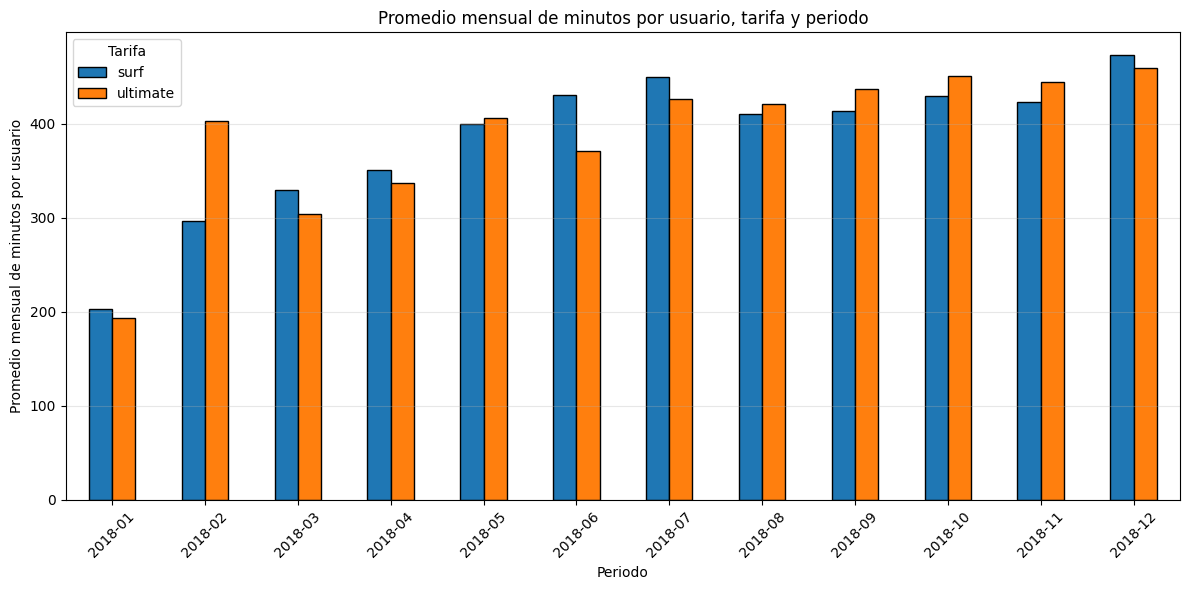

In [ ]:
# 32
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.
average_monthly_minutes = (
    monthly_usage.groupby(['year_month', 'plan'])['minutes_used']
    .mean()
    .unstack()
)

average_monthly_minutes.plot(
    kind='bar',
    figsize=(12, 6),
    edgecolor='black'
)

plt.title('Promedio mensual de minutos por usuario, tarifa y periodo')
plt.xlabel('Periodo')
plt.ylabel('Promedio mensual de minutos por usuario')
plt.xticks(rotation=45)
plt.legend(title='Tarifa')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos sobre los minutos mensuales</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El promedio mensual de minutos por usuario aumenta de manera general en ambas tarifas conforme avanza el año.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ninguna tarifa presenta valores superiores de forma constante: las diferencias cambian de dirección entre periodos y se reducen durante varios meses de la segunda mitad del año.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Descriptivamente, el plan contratado no parece producir un patrón claramente distinto en el uso mensual de llamadas; esta observación deberá contrastarse con las medidas de dispersión y las distribuciones posteriores.</FONT><br>

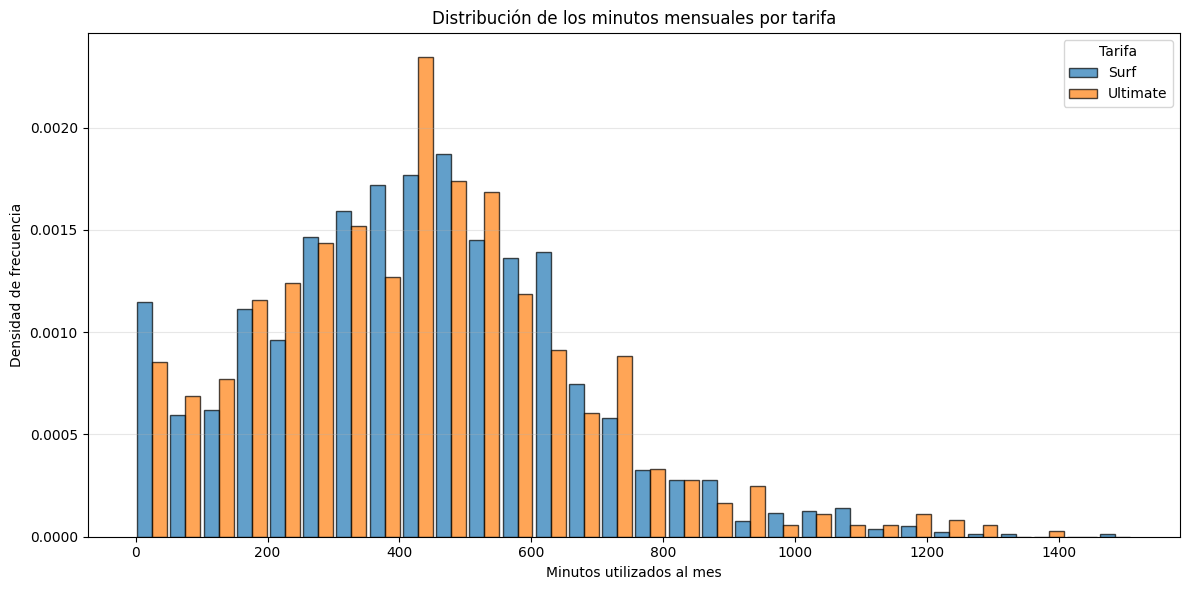

In [ ]:
# 33
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.
surf_minutes = monthly_usage.loc[
    monthly_usage['plan'] == 'surf',
    'minutes_used'
]

ultimate_minutes = monthly_usage.loc[
    monthly_usage['plan'] == 'ultimate',
    'minutes_used'
]

plt.figure(figsize=(12, 6))

plt.hist(
    [surf_minutes, ultimate_minutes],
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor='black',
    rwidth=0.9,
    label=['Surf', 'Ultimate']
)

plt.title('Distribución de los minutos mensuales por tarifa')
plt.xlabel('Minutos utilizados al mes')
plt.ylabel('Densidad de frecuencia')
plt.legend(title='Tarifa')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos sobre la distribución de minutos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las distribuciones de Surf y Ultimate presentan una amplia superposición y concentran la mayor densidad aproximadamente entre 300 y 600 minutos mensuales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ambas distribuciones muestran asimetría positiva, con colas que se extienden hacia consumos superiores a 1,000 minutos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Una parte de los registros de Surf supera los 500 minutos incluidos, por lo que puede generar cargos adicionales; los consumos observados de Ultimate permanecen muy por debajo de su límite de 3,000 minutos.</FONT><br>

- <b><FONT SIZE=5 COLOR="F5950F">Comparación estadística de las llamadas</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se calcularán la media, la varianza y la desviación estándar de `minutes_used` para cada tarifa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Estas medidas permitirán comparar el consumo mensual promedio y la dispersión de los minutos utilizados por los usuarios de Surf y Ultimate.</FONT><br>

In [ ]:
# 34
# Calcula la media, la varianza y la desviación estándar de la duración mensual de llamadas.
call_statistics = (
    monthly_usage.groupby('plan')['minutes_used']
    .agg(['mean', 'var', 'std'])
    .reset_index()
)

call_statistics = call_statistics.rename(
    columns={
        'mean': 'mean_minutes',
        'var': 'variance_minutes',
        'std': 'standard_deviation_minutes'
    }
)

call_statistics.round(2)

,plan,mean_minutes,variance_minutes,standard_deviation_minutes
0,surf,428.75,54968.28,234.45
1,ultimate,430.45,57844.46,240.51


- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos estadísticos sobre las llamadas</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los promedios mensuales son prácticamente iguales: 428.75 minutos para Surf y 430.45 para Ultimate, una diferencia de solo 1.70 minutos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La dispersión también es similar, aunque Ultimate presenta una varianza y una desviación estándar ligeramente mayores.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las desviaciones estándar superiores a 230 minutos confirman una variabilidad considerable dentro de ambas tarifas, consistente con las colas observadas en el histograma.</FONT><br>

/tmp/ipykernel_39628/2709550727.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = axes[1].boxplot(


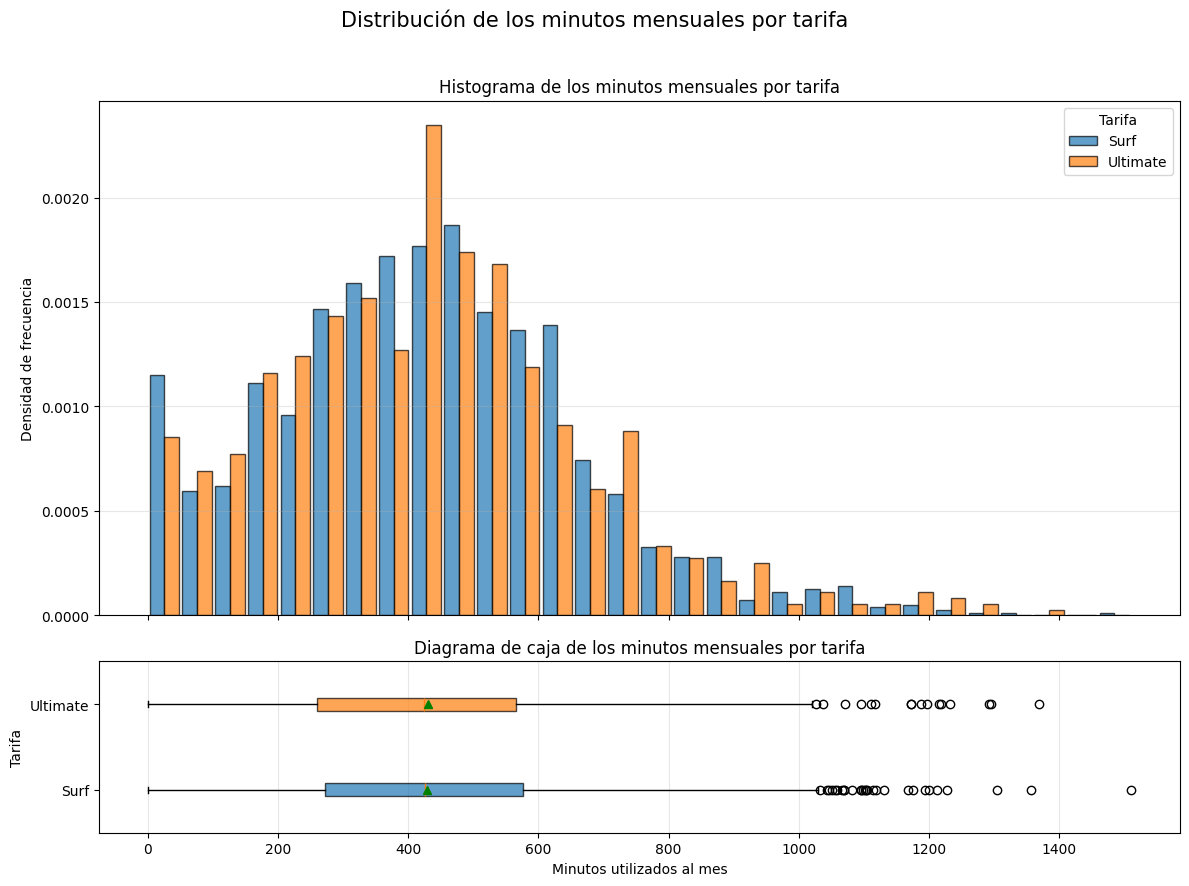

In [ ]:
# 35
# Comparar las distribuciones mediante un histograma y un diagrama de caja
fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

# Histograma
axes[0].hist(
    [surf_minutes, ultimate_minutes],
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor='black',
    rwidth=0.9,
    label=['Surf', 'Ultimate']
)

axes[0].set_title('Histograma de los minutos mensuales por tarifa')
axes[0].set_ylabel('Densidad de frecuencia')
axes[0].legend(title='Tarifa')
axes[0].grid(axis='y', alpha=0.3)

# Diagrama de caja horizontal
boxplot = axes[1].boxplot(
    [surf_minutes, ultimate_minutes],
    labels=['Surf', 'Ultimate'],
    vert=False,
    patch_artist=True,
    showmeans=True,
    meanprops={
        'marker': '^',
        'markerfacecolor': 'green',
        'markeredgecolor': 'green'
    }
)

for box, color in zip(
    boxplot['boxes'],
    ['tab:blue', 'tab:orange']
):
    box.set_facecolor(color)
    box.set_alpha(0.7)

axes[1].set_title('Diagrama de caja de los minutos mensuales por tarifa')
axes[1].set_xlabel('Minutos utilizados al mes')
axes[1].set_ylabel('Tarifa')
axes[1].grid(axis='x', alpha=0.3)

fig.suptitle(
    'Distribución de los minutos mensuales por tarifa',
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos del diagrama de caja</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf y Ultimate presentan medianas, medias y rangos intercuartílicos muy similares, lo que confirma un comportamiento central comparable.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">En ambas tarifas aparecen numerosos valores atípicos por encima de aproximadamente 1,000 minutos mensuales, coherentes con la asimetría positiva observada en el histograma.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf alcanza los consumos extremos más altos, pero la estructura general de ambas distribuciones permanece semejante.</FONT><br>

- <b><FONT SIZE=6 COLOR="F5950F">Conclusión integrada sobre el centro y la dispersión</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las distribuciones presentan una amplia superposición: las medianas se sitúan cerca de 425 minutos, mientras que los promedios son de 428.75 minutos para Surf y 430.45 para Ultimate.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El `50%` central de las observaciones se concentra aproximadamente entre 260 y 575 minutos mensuales en ambos planes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate muestra una variabilidad ligeramente mayor, con una desviación estándar de 240.51 minutos frente a 234.45 en Surf; por tanto, Surf es solo marginalmente más predecible.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia entre los promedios de las tarifas es mínima frente a la dispersión existente dentro de cada grupo.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Forma de las distribuciones y valores atípicos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ambas distribuciones presentan asimetría positiva y numerosos valores atípicos superiores a 1,000 minutos mensuales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los casos más extremos se aproximan a 1,510 minutos en Surf y 1,370 en Ultimate; estos consumos pueden ser reales y no deben eliminarse automáticamente como errores.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Implicación para las tarifas</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Descriptivamente, el plan contratado no produce una diferencia importante en el comportamiento mensual de llamadas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia relevante aparece en la facturación: una fracción visible de los registros de Surf alcanza o supera los 500 minutos incluidos, mientras que los consumos de Ultimate permanecen muy lejos de su límite de 3,000 minutos.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Mensajes <a id='subtitle'></FONT></b>

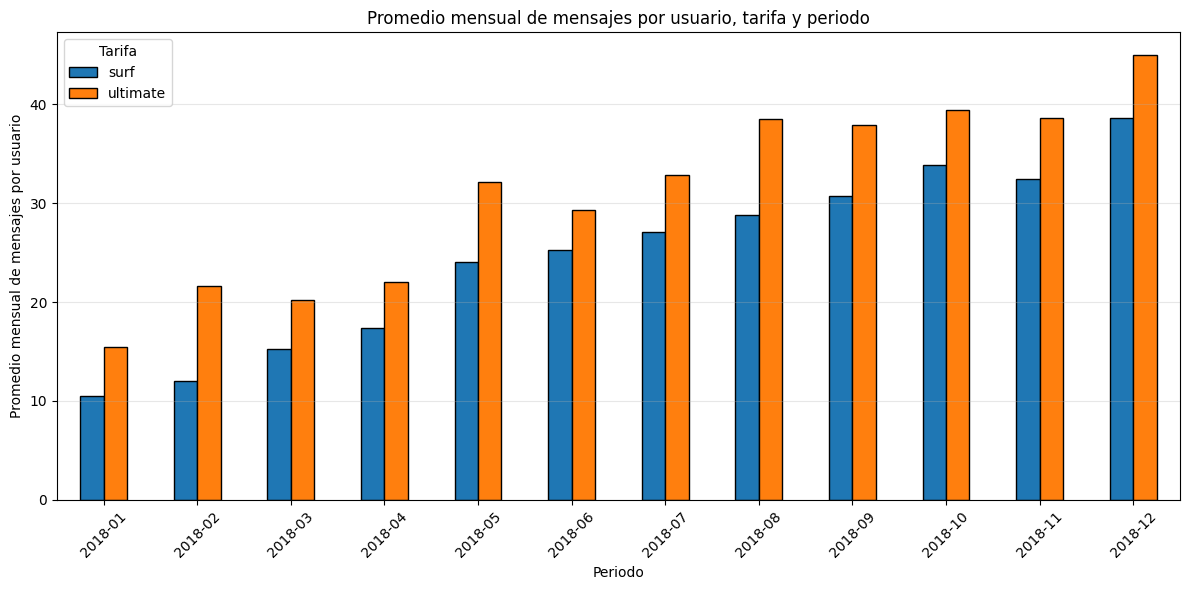

In [ ]:
# 36
# Compara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan
average_monthly_messages = (
    monthly_usage.groupby(['year_month', 'plan'])['messages_count']
    .mean()
    .unstack()
)

average_monthly_messages.plot(
    kind='bar',
    figsize=(12, 6),
    edgecolor='black'
)

plt.title('Promedio mensual de mensajes por usuario, tarifa y periodo')
plt.xlabel('Periodo')
plt.ylabel('Promedio mensual de mensajes por usuario')
plt.xticks(rotation=45)
plt.legend(title='Tarifa')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos sobre los mensajes mensuales</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El promedio mensual de mensajes aumenta de manera general en ambas tarifas conforme avanza el año.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate mantiene un promedio superior al de Surf en todos los periodos observados, aunque el tamaño de la diferencia varía entre meses.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los promedios mensuales permanecen por debajo de los límites incluidos de 50 mensajes para Surf y 1,000 para Ultimate; sin embargo, el promedio no descarta que usuarios individuales de Surf generen excedentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Al contrastar estos promedios con las condiciones de las tarifas, ambos permanecen por debajo de los límites incluidos: 50 mensajes para Surf y 1,000 para Ultimate. Sin embargo, el promedio no descarta que usuarios individuales de Surf generen excedentes.</FONT><br>

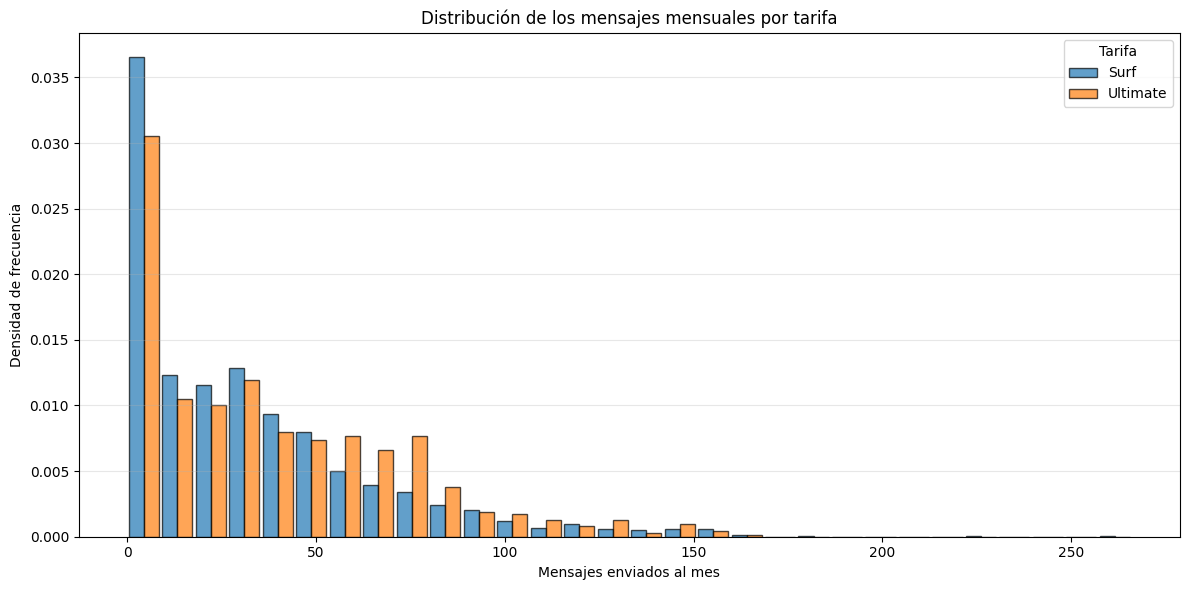

In [ ]:
# 37
# Compara la distribución de los mensajes mensuales de los usuarios de cada plan. Traza un histograma.
surf_messages = monthly_usage.loc[
    monthly_usage['plan'] == 'surf',
    'messages_count'
]

ultimate_messages = monthly_usage.loc[
    monthly_usage['plan'] == 'ultimate',
    'messages_count'
]

plt.figure(figsize=(12, 6))

plt.hist(
    [surf_messages, ultimate_messages],
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor='black',
    rwidth=0.9,
    label=['Surf', 'Ultimate']
)

plt.title('Distribución de los mensajes mensuales por tarifa')
plt.xlabel('Mensajes enviados al mes')
plt.ylabel('Densidad de frecuencia')
plt.legend(title='Tarifa')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos del histograma de mensajes</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ambas distribuciones presentan una fuerte asimetría positiva y una elevada concentración de registros con pocos o ningún mensaje enviado.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate muestra una mayor densidad relativa en varios intervalos comprendidos aproximadamente entre 50 y 90 mensajes, mientras que Surf concentra más observaciones cerca de cero.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf presenta la cola más extensa, con consumos superiores a 250 mensajes; además, parte de sus registros supera los 50 mensajes incluidos. Ultimate permanece muy por debajo de su límite mensual de 1,000 mensajes.</FONT><br>

/tmp/ipykernel_39628/3523981582.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  message_boxplot = axes[1].boxplot(


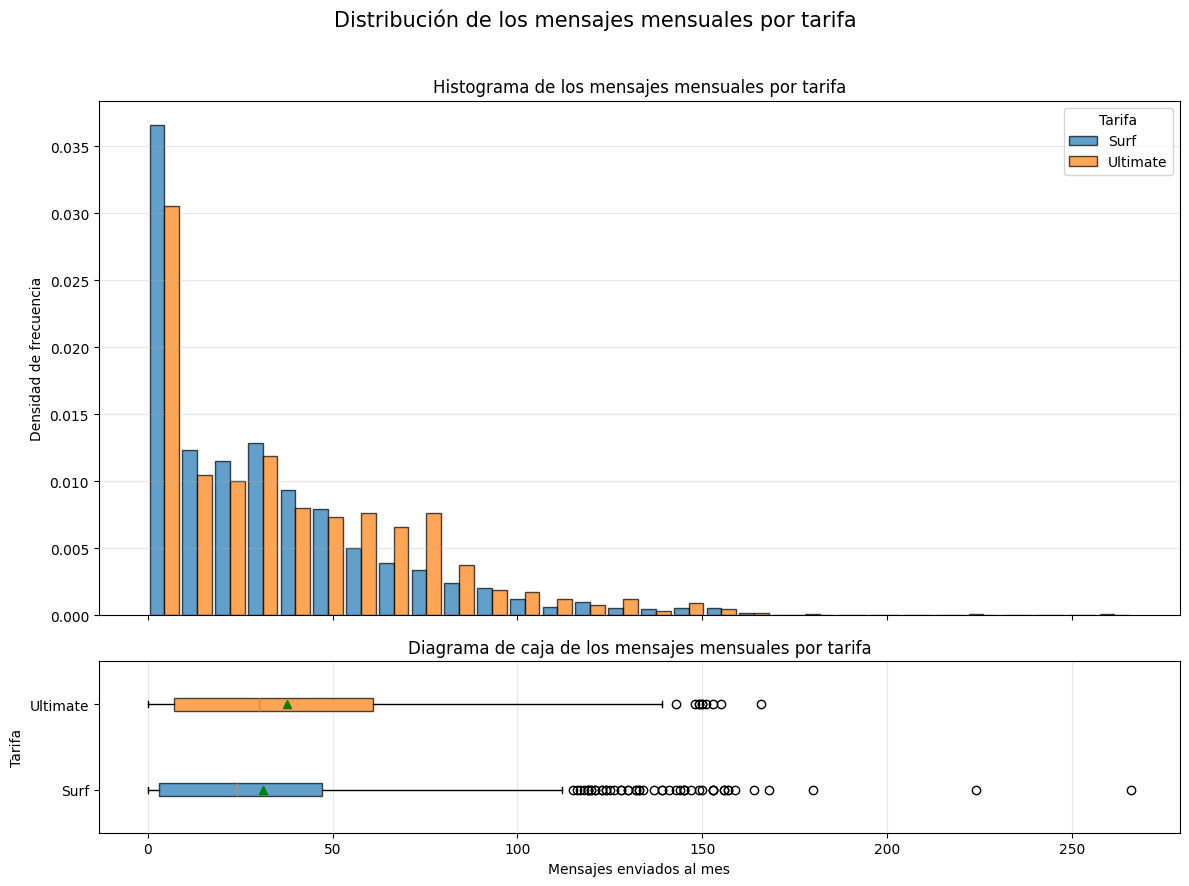

In [ ]:
# 38
# Integra el histograma y el diagrama de caja de los mensajes mensuales
fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

# Histograma
axes[0].hist(
    [surf_messages, ultimate_messages],
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor='black',
    rwidth=0.9,
    label=['Surf', 'Ultimate']
)

axes[0].set_title('Histograma de los mensajes mensuales por tarifa')
axes[0].set_ylabel('Densidad de frecuencia')
axes[0].legend(title='Tarifa')
axes[0].grid(axis='y', alpha=0.3)

# Diagrama de caja horizontal
message_boxplot = axes[1].boxplot(
    [surf_messages, ultimate_messages],
    labels=['Surf', 'Ultimate'],
    vert=False,
    patch_artist=True,
    showmeans=True,
    meanprops={
        'marker': '^',
        'markerfacecolor': 'green',
        'markeredgecolor': 'green'
    }
)

for box, color in zip(
    message_boxplot['boxes'],
    ['tab:blue', 'tab:orange']
):
    box.set_facecolor(color)
    box.set_alpha(0.7)

axes[1].set_title('Diagrama de caja de los mensajes mensuales por tarifa')
axes[1].set_xlabel('Mensajes enviados al mes')
axes[1].set_ylabel('Tarifa')
axes[1].grid(axis='x', alpha=0.3)

fig.suptitle(
    'Distribución de los mensajes mensuales por tarifa',
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos del diagrama de caja de mensajes</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate presenta una mediana y un rango intercuartílico superiores a los de Surf, lo que indica un mayor consumo habitual de mensajes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">En ambas tarifas, la media se encuentra por encima de la mediana, confirmando la asimetría positiva observada en el histograma.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf concentra una mayor cantidad de valores atípicos y alcanza los casos más extremos, cercanos a 266 mensajes mensuales; estos registros pueden representar consumos reales y no deben eliminarse automáticamente.</FONT><br>

In [ ]:
# 39
# Calcula la media, la varianza y la desviación estándar de los mensajes mensuales
message_statistics = (
    monthly_usage.groupby('plan')['messages_count']
    .agg(['mean', 'var', 'std'])
    .reset_index()
)

message_statistics = message_statistics.rename(
    columns={
        'mean': 'mean_messages',
        'var': 'variance_messages',
        'std': 'standard_deviation_messages'
    }
)

message_statistics.round(2)

,plan,mean_messages,variance_messages,standard_deviation_messages
0,surf,31.16,1126.72,33.57
1,ultimate,37.55,1208.76,34.77


- <b><FONT SIZE=5 COLOR="FB7BEF">Resultados estadísticos de los mensajes</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los usuarios de Ultimate envían en promedio 37.55 mensajes mensuales, frente a 31.16 en Surf, una diferencia descriptiva de 6.39 mensajes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate presenta una varianza de 1,208.76 y una desviación estándar de 34.77 mensajes; Surf registra una varianza de 1,126.72 y una desviación estándar de 33.57.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La dispersión es elevada y semejante en ambos planes, aunque Ultimate muestra una variabilidad absoluta ligeramente mayor.</FONT><br>

- <b><FONT SIZE=6 COLOR="F5950F">Conclusiones sobre el comportamiento de mensajes</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los usuarios de Ultimate enviaron en promedio 37.55 mensajes mensuales, mientras que los usuarios de Surf enviaron 31.16. La diferencia es de 6.39 mensajes, equivalente a aproximadamente un 20.5% más en Ultimate.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate mantuvo un promedio superior al de Surf en los doce periodos analizados, por lo que la diferencia no corresponde únicamente a un mes aislado.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La varianza fue de 1,208.76 mensajes² en Ultimate y 1,126.72 mensajes² en Surf; las desviaciones estándar fueron de 34.77 y 33.57 mensajes, respectivamente.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia de solo 1.20 mensajes entre las desviaciones estándar indica que ambas tarifas presentan una dispersión absoluta semejante, aunque Ultimate es ligeramente más variable.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia entre las medias, de 6.39 mensajes, es considerablemente menor que las desviaciones estándar cercanas a 34 mensajes; por ello, existe una amplia superposición entre las distribuciones y una elevada heterogeneidad dentro de cada tarifa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ambas distribuciones presentan asimetría positiva. Surf alcanza valores atípicos cercanos a 266 mensajes mensuales, mientras que los casos extremos de Ultimate se aproximan a 166.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Implicación para las tarifas</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Aunque el promedio de Surf permanece por debajo de sus 50 mensajes incluidos, parte de su distribución supera ese límite y puede generar cargos adicionales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate presenta un consumo promedio mayor, pero todos los valores observados permanecen muy por debajo de los 1,000 mensajes incluidos, por lo que los mensajes difícilmente generan excedentes en esta tarifa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Descriptivamente, el comportamiento sí varía según el plan: Ultimate muestra un consumo mensual habitual mayor, pero las diferencias entre usuarios dentro de cada tarifa superan ampliamente la diferencia promedio entre los planes.</FONT><br>

### <b> <FONT SIZE=6 COLOR="F5950F"> Internet <a id='internet_behavior'></FONT></b>

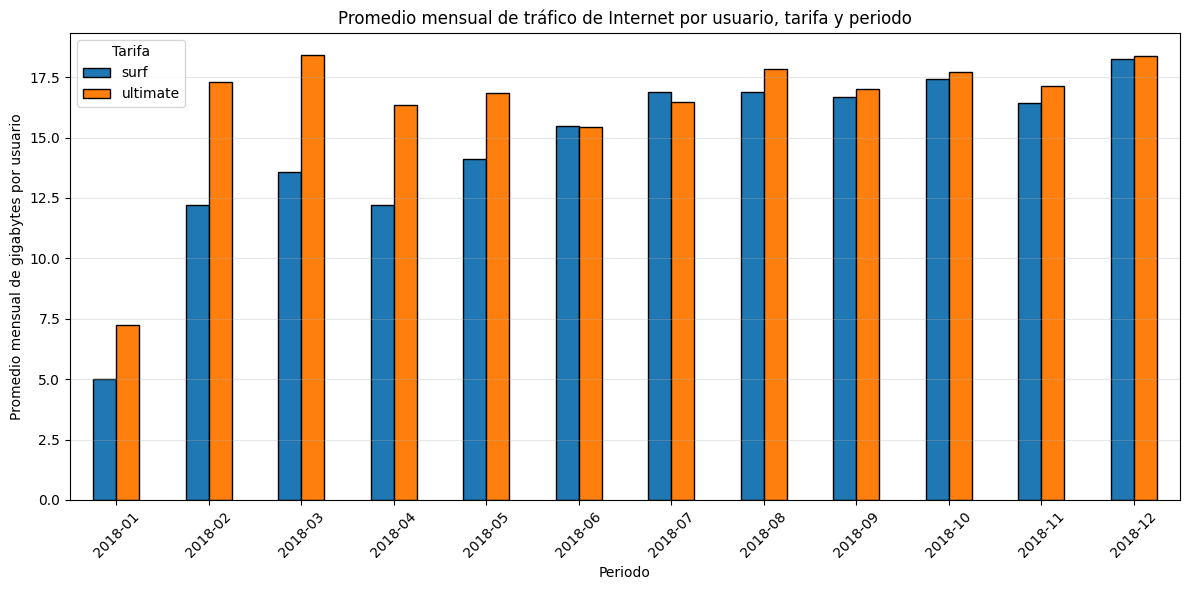

In [ ]:
# 40
# Compara el consumo promedio mensual de Internet por cada plan y periodo
average_monthly_internet = (
    monthly_usage.groupby(['year_month', 'plan'])['gb_used']
    .mean()
    .unstack()
)

average_monthly_internet.plot(
    kind='bar',
    figsize=(12, 6),
    edgecolor='black'
)

plt.title('Promedio mensual de tráfico de Internet por usuario, tarifa y periodo')
plt.xlabel('Periodo')
plt.ylabel('Promedio mensual de gigabytes por usuario')
plt.xticks(rotation=45)
plt.legend(title='Tarifa')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos sobre el consumo mensual de Internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El consumo promedio aumenta durante los primeros meses y posteriormente se concentra aproximadamente entre 15 y 18.5 GB por usuario en ambas tarifas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate presenta un promedio superior en la mayoría de los periodos, aunque las diferencias entre tarifas se reducen considerablemente durante la segunda mitad del año y Surf supera ligeramente a Ultimate en junio y julio.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Al contrastar los resultados con las condiciones tarifarias, el promedio de Surf alcanza o supera sus 15 GB incluidos desde junio, mientras que Ultimate permanece muy por debajo de su límite mensual de 30 GB.</FONT><br>

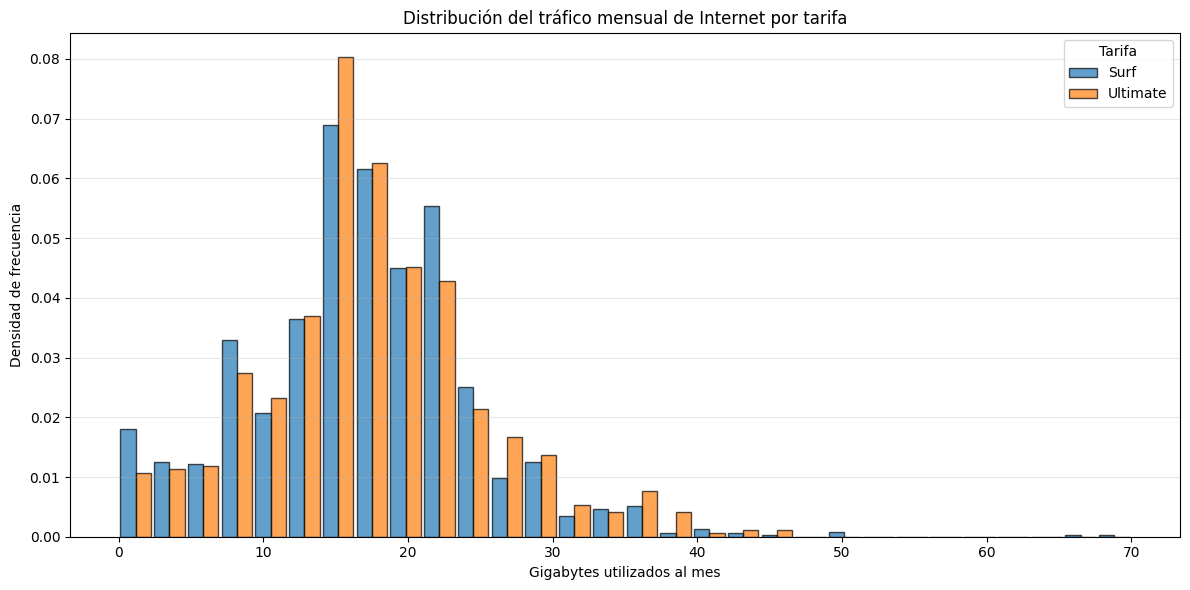

In [ ]:
# 41
# Compara la distribución del tráfico mensual de Internet de los usuarios de cada plan. Traza un histograma.
surf_internet = monthly_usage.loc[
    monthly_usage['plan'] == 'surf',
    'gb_used'
]

ultimate_internet = monthly_usage.loc[
    monthly_usage['plan'] == 'ultimate',
    'gb_used'
]

plt.figure(figsize=(12, 6))

plt.hist(
    [surf_internet, ultimate_internet],
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor='black',
    rwidth=0.9,
    label=['Surf', 'Ultimate']
)

plt.title('Distribución del tráfico mensual de Internet por tarifa')
plt.xlabel('Gigabytes utilizados al mes')
plt.ylabel('Densidad de frecuencia')
plt.legend(title='Tarifa')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos del histograma de Internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las distribuciones presentan una amplia superposición y concentran su mayor densidad aproximadamente entre 14 y 22 GB mensuales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ambas tarifas muestran asimetría positiva, aunque Surf tiene la cola más extensa, con consumos extremos cercanos a 70 GB; Ultimate alcanza valores aproximados de 46 GB.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Al comparar las distribuciones con los límites tarifarios, numerosos registros de Surf superan los 15 GB incluidos, mientras que solo una fracción de Ultimate excede su límite de 30 GB.</FONT><br>

/tmp/ipykernel_39628/445694045.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  internet_boxplot = axes[1].boxplot(


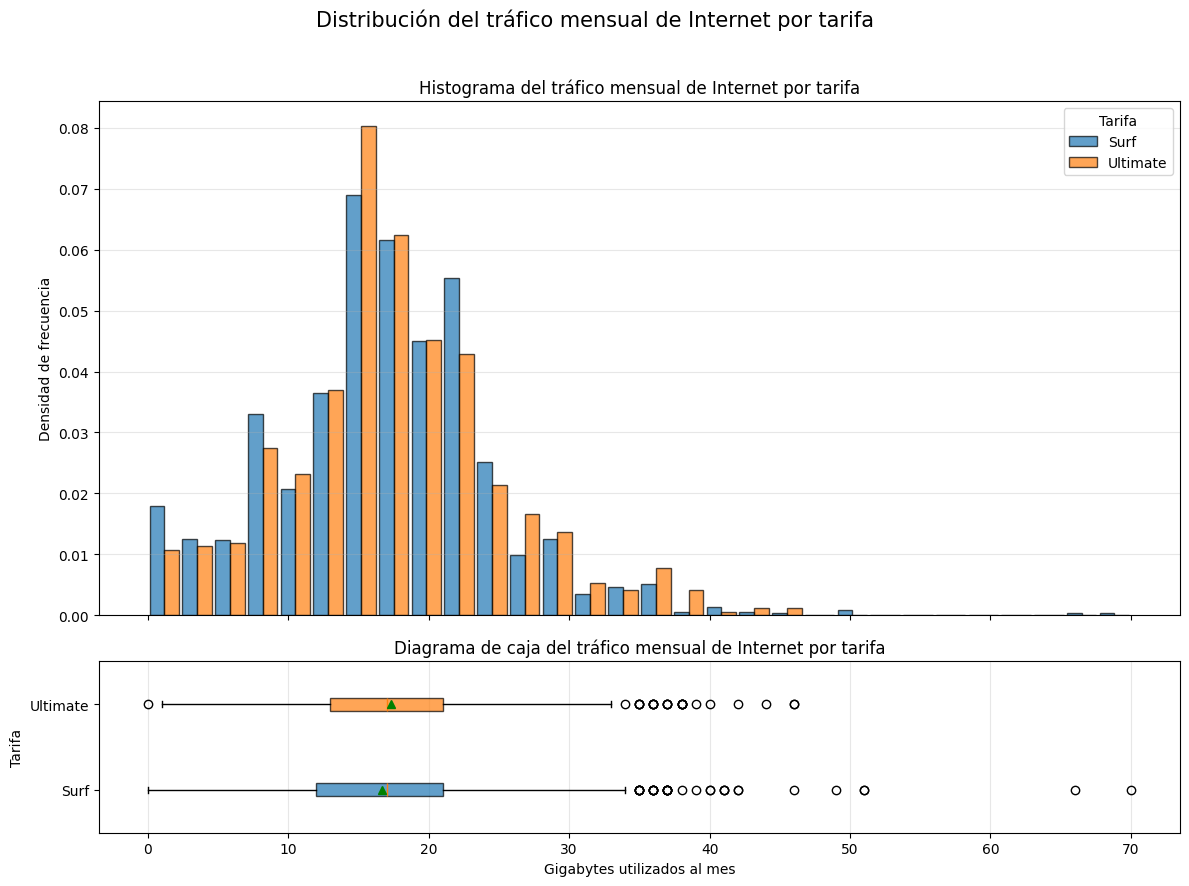

In [ ]:
# 42
# Integra el histograma y el diagrama de caja del tráfico mensual de Internet
fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

# Histograma
axes[0].hist(
    [surf_internet, ultimate_internet],
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor='black',
    rwidth=0.9,
    label=['Surf', 'Ultimate']
)

axes[0].set_title('Histograma del tráfico mensual de Internet por tarifa')
axes[0].set_ylabel('Densidad de frecuencia')
axes[0].legend(title='Tarifa')
axes[0].grid(axis='y', alpha=0.3)

# Diagrama de caja horizontal
internet_boxplot = axes[1].boxplot(
    [surf_internet, ultimate_internet],
    labels=['Surf', 'Ultimate'],
    vert=False,
    patch_artist=True,
    showmeans=True,
    meanprops={
        'marker': '^',
        'markerfacecolor': 'green',
        'markeredgecolor': 'green'
    }
)

for box, color in zip(
    internet_boxplot['boxes'],
    ['tab:blue', 'tab:orange']
):
    box.set_facecolor(color)
    box.set_alpha(0.7)

axes[1].set_title('Diagrama de caja del tráfico mensual de Internet por tarifa')
axes[1].set_xlabel('Gigabytes utilizados al mes')
axes[1].set_ylabel('Tarifa')
axes[1].grid(axis='x', alpha=0.3)

fig.suptitle(
    'Distribución del tráfico mensual de Internet por tarifa',
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos de la distribución integrada de Internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las medianas, medias y rangos intercuartílicos de Surf y Ultimate son muy similares, lo que confirma una amplia superposición entre las distribuciones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">En ambas tarifas, la mayor parte del consumo se concentra aproximadamente entre 12 y 22 GB mensuales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las colas derechas y los valores atípicos confirman asimetría positiva. Surf presenta los consumos más extremos, con registros cercanos a 66 y 70 GB, mientras que Ultimate alcanza aproximadamente 46 GB.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia más relevante para el negocio no se encuentra en el centro de las distribuciones, sino en los límites incluidos: 15 GB para Surf frente a 30 GB para Ultimate.</FONT><br>

In [ ]:
# 43
# Calcula la media, la varianza y la desviación estándar del tráfico mensual de Internet
internet_statistics = (
    monthly_usage.groupby('plan')['gb_used']
    .agg(['mean', 'var', 'std'])
    .reset_index()
)

internet_statistics = internet_statistics.rename(
    columns={
        'mean': 'mean_gb',
        'var': 'variance_gb',
        'std': 'standard_deviation_gb'
    }
)

internet_statistics.round(2)

,plan,mean_gb,variance_gb,standard_deviation_gb
0,surf,16.67,61.58,7.85
1,ultimate,17.31,58.83,7.67


- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos estadísticos del consumo de Internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los usuarios de Ultimate consumen en promedio 17.31 GB mensuales, frente a 16.67 GB en Surf; la diferencia es de 0.64 GB.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf presenta una varianza de 61.58 GB² y una desviación estándar de 7.85 GB, mientras que Ultimate registra una varianza de 58.83 GB² y una desviación estándar de 7.67 GB.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf muestra una variabilidad ligeramente mayor, aunque la diferencia de 0.18 GB entre las desviaciones estándar es mínima.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia de 0.64 GB entre los promedios es considerablemente menor que las desviaciones estándar cercanas a 8 GB, lo que indica una amplia superposición entre ambas tarifas.</FONT><br>

In [ ]:
# 44
# Calcula la cantidad y proporción de registros usuario-periodo que exceden el límite de Internet
internet_overage_summary = (
    monthly_usage.assign(
        exceeds_internet_limit=(
            monthly_usage['gb_used']
            > monthly_usage['gb_per_month_included']
        )
    )
    .groupby('plan')['exceeds_internet_limit']
    .agg(['sum', 'count', 'mean'])
    .reset_index()
)

internet_overage_summary = internet_overage_summary.rename(
    columns={
        'sum': 'overage_user_periods',
        'count': 'total_user_periods',
        'mean': 'overage_proportion'
    }
)

internet_overage_summary['overage_percentage'] = (
    internet_overage_summary['overage_proportion'] * 100
).round(2)

internet_overage_summary[
    [
        'plan',
        'overage_user_periods',
        'total_user_periods',
        'overage_percentage'
    ]
]

,plan,overage_user_periods,total_user_periods,overage_percentage
0,surf,911,1573,57.91
1,ultimate,41,720,5.69


- <b><FONT SIZE=5 COLOR="FB7BEF">Frecuencia de excedentes de Internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf superó su límite de 15 GB en 911 de 1,573 registros usuario-periodo, equivalentes al 57.91%.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate superó su límite de 30 GB en 41 de 720 registros usuario-periodo, equivalentes al 5.69%.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La frecuencia de excedentes de Surf es aproximadamente 10.2 veces la de Ultimate, con una diferencia de 52.22 puntos porcentuales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Estos resultados confirman cuantitativamente que los usuarios-periodo de Surf tienen una exposición considerablemente mayor a cargos adicionales por Internet.</FONT><br>

- <b><FONT SIZE=6 COLOR="F5950F">Conclusiones sobre el comportamiento de Internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los usuarios de Ultimate consumen en promedio 17.31 GB mensuales y los de Surf 16.67 GB. La diferencia es de solo 0.64 GB, aproximadamente el 3.8% del promedio de Surf.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La dispersión también es muy semejante: Surf presenta una desviación estándar de 7.85 GB y Ultimate de 7.67 GB, una diferencia de únicamente 0.18 GB.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los histogramas y diagramas de caja muestran una amplia superposición, concentración principal entre aproximadamente 12 y 22 GB y asimetría positiva en ambas tarifas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf registra los consumos atípicos más elevados, cercanos a 70 GB mensuales, mientras que Ultimate alcanza aproximadamente 46 GB.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Descriptivamente, el consumo central es similar entre planes; la diferencia principal no se encuentra en cuánto consumen en promedio, sino en los límites incluidos en cada tarifa.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Excedentes e implicación tarifaria</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf superó sus 15 GB incluidos en 911 de 1,573 registros usuario-periodo, equivalentes al 57.91%.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate superó sus 30 GB incluidos en 41 de 720 registros usuario-periodo, equivalentes al 5.69%.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los excedentes fueron aproximadamente 10.2 veces más frecuentes en Surf, con una diferencia de 52.22 puntos porcentuales respecto a Ultimate.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Esta diferencia confirma que Surf tiene una exposición considerablemente mayor a cargos adicionales por Internet. Además, cada gigabyte excedente cuesta 10 USD en Surf, frente a 7 USD en Ultimate.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Por tanto, aunque el consumo promedio de ambas tarifas es parecido, las condiciones de Surf convierten el tráfico de Internet en una fuente mucho más frecuente de ingresos adicionales.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F">Ingreso <a id='revenue_behavior'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Objetivo del análisis estadístico de los ingresos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los ingresos mensuales se estudiarán por tarifa y registro usuario-periodo para comparar el comportamiento de Surf y Ultimate.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Primero se analizará la evolución del ingreso promedio durante los periodos de 2018, con el propósito de identificar cambios temporales y diferencias descriptivas entre las tarifas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Después se utilizarán un histograma de densidad y un diagrama de caja integrado para comparar la concentración, dispersión, asimetría y presencia de valores atípicos en ambas distribuciones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Finalmente, se calcularán la media, la mediana, la varianza y la desviación estándar para cuantificar el centro y la variabilidad de los ingresos mensuales.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Alcance de la comparación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El análisis descriptivo permitirá identificar cuál tarifa presenta el mayor ingreso promedio observado y cuál genera ingresos más estables.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se analizarán ingresos y no rentabilidad, ya que el conjunto de datos no contiene información sobre los costos de proporcionar el servicio.</FONT><br>

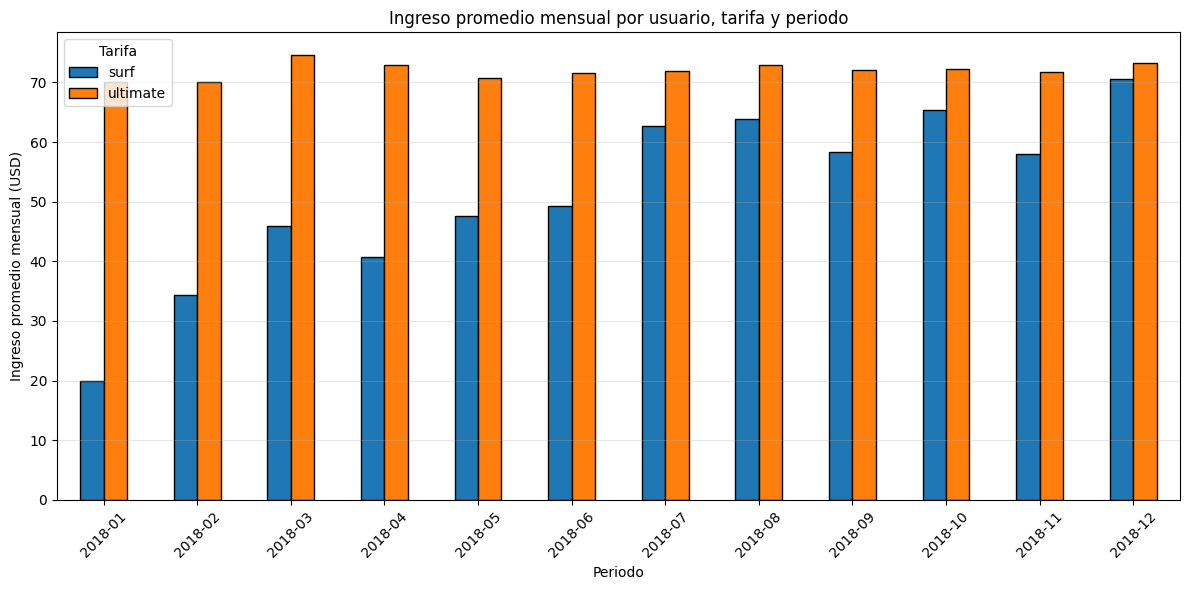

In [ ]:
# 45
# Compara el ingreso promedio mensual por cada plan y periodo
average_monthly_revenue = (
    monthly_usage.groupby(['year_month', 'plan'])['monthly_revenue']
    .mean()
    .unstack()
)

average_monthly_revenue.plot(
    kind='bar',
    figsize=(12, 6),
    edgecolor='black'
)

plt.title('Ingreso promedio mensual por usuario, tarifa y periodo')
plt.xlabel('Periodo')
plt.ylabel('Ingreso promedio mensual (USD)')
plt.xticks(rotation=45)
plt.legend(title='Tarifa')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos sobre la evolución mensual de los ingresos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate mantiene un ingreso promedio superior al de Surf en los doce periodos analizados y permanece relativamente estable alrededor de 70–75 USD.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El ingreso promedio de Surf aumenta de 20 USD en enero a poco más de 70 USD en diciembre, aunque presenta fluctuaciones durante el año.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia entre las tarifas se reduce conforme avanza el periodo: Ultimate domina ampliamente al inicio, pero los promedios se aproximan en diciembre.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Al contrastar el gráfico con las condiciones tarifarias, Ultimate permanece cerca de su cuota base de 70 USD, mientras que el crecimiento de Surf por encima de sus 20 USD refleja la acumulación de cargos por excedentes.</FONT><br>

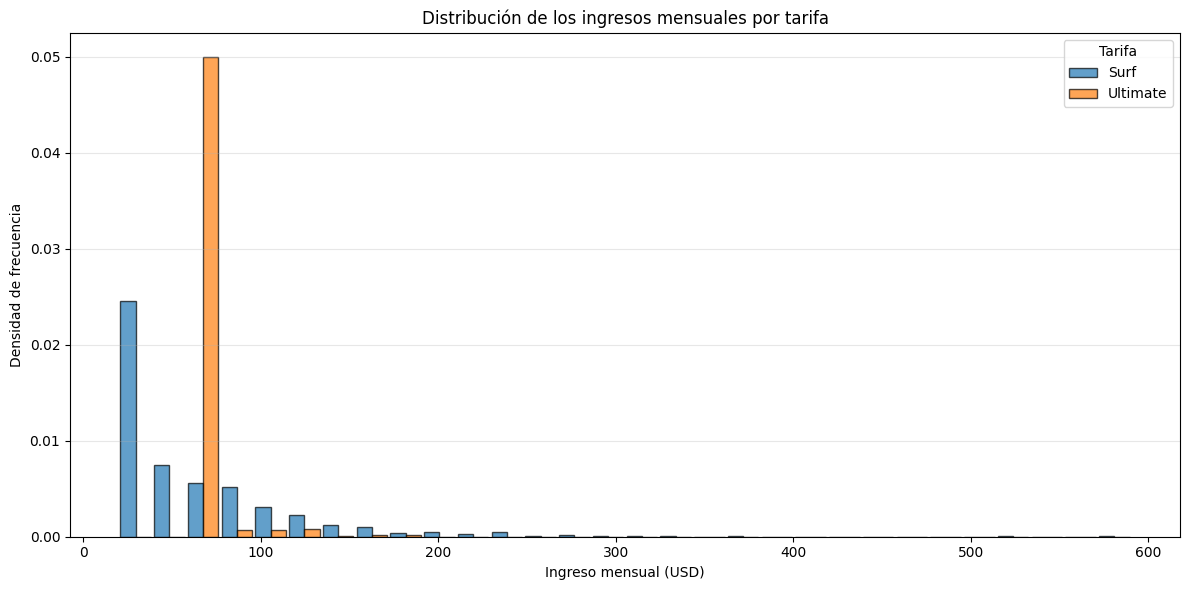

In [ ]:
# 46
# Compara la distribución de los ingresos mensuales de los usuarios de cada plan. Traza un histograma.
surf_revenue = monthly_usage.loc[
    monthly_usage['plan'] == 'surf',
    'monthly_revenue'
]

ultimate_revenue = monthly_usage.loc[
    monthly_usage['plan'] == 'ultimate',
    'monthly_revenue'
]

plt.figure(figsize=(12, 6))

plt.hist(
    [surf_revenue, ultimate_revenue],
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor='black',
    rwidth=0.9,
    label=['Surf', 'Ultimate']
)

plt.title('Distribución de los ingresos mensuales por tarifa')
plt.xlabel('Ingreso mensual (USD)')
plt.ylabel('Densidad de frecuencia')
plt.legend(title='Tarifa')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos del histograma de ingresos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate presenta una concentración muy pronunciada alrededor de 70 USD, correspondiente a su cuota mensual, y relativamente pocos registros con cargos adicionales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf concentra numerosos registros cerca de su cuota base de 20 USD, pero muestra una distribución mucho más extendida y una fuerte asimetría positiva.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La cola de Surf alcanza ingresos cercanos a 600 USD, mientras que Ultimate permanece aproximadamente por debajo de 190 USD; esto anticipa una variabilidad considerablemente mayor en Surf debido a los excedentes.</FONT><br>

/tmp/ipykernel_39628/1781141614.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  revenue_boxplot = axes[1].boxplot(


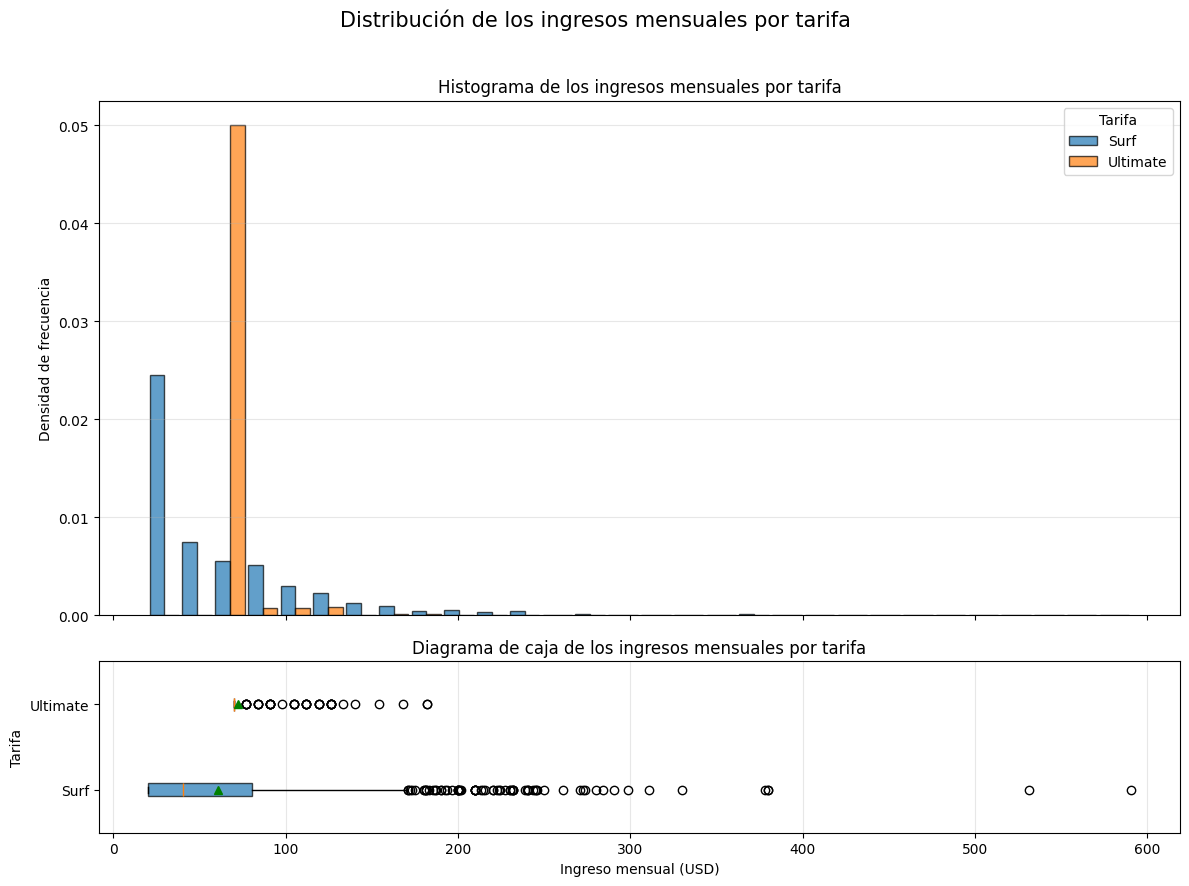

In [ ]:
# 47
# Integra el histograma y el diagrama de caja de los ingresos mensuales
fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

# Histograma
axes[0].hist(
    [surf_revenue, ultimate_revenue],
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor='black',
    rwidth=0.9,
    label=['Surf', 'Ultimate']
)

axes[0].set_title('Histograma de los ingresos mensuales por tarifa')
axes[0].set_ylabel('Densidad de frecuencia')
axes[0].legend(title='Tarifa')
axes[0].grid(axis='y', alpha=0.3)

# Diagrama de caja horizontal
revenue_boxplot = axes[1].boxplot(
    [surf_revenue, ultimate_revenue],
    labels=['Surf', 'Ultimate'],
    vert=False,
    patch_artist=True,
    showmeans=True,
    meanprops={
        'marker': '^',
        'markerfacecolor': 'green',
        'markeredgecolor': 'green'
    }
)

for box, color in zip(
    revenue_boxplot['boxes'],
    ['tab:blue', 'tab:orange']
):
    box.set_facecolor(color)
    box.set_alpha(0.7)

axes[1].set_title('Diagrama de caja de los ingresos mensuales por tarifa')
axes[1].set_xlabel('Ingreso mensual (USD)')
axes[1].set_ylabel('Tarifa')
axes[1].grid(axis='x', alpha=0.3)

fig.suptitle(
    'Distribución de los ingresos mensuales por tarifa',
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos de la distribución integrada de ingresos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate concentra la mayor parte de sus registros exactamente alrededor de 70 USD, por lo que su caja es muy estrecha y refleja ingresos mensuales altamente estables.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf presenta una mediana cercana a 40 USD, una media visiblemente superior y un rango intercuartílico mucho más amplio, lo que confirma una marcada asimetría positiva.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores atípicos de Ultimate alcanzan aproximadamente 180 USD, mientras que Surf presenta numerosos casos por encima de 170 USD y extremos cercanos a 590 USD.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La estructura de Ultimate produce ingresos previsibles alrededor de su cuota base; Surf genera ingresos menos estables, pero con mayor potencial de crecimiento mediante cargos por excedentes.</FONT><br>

In [ ]:
# 48
# Calcula la media, la mediana, la varianza y la desviación estándar de los ingresos mensuales
revenue_statistics = (
    monthly_usage.groupby('plan')['monthly_revenue']
    .agg(['mean', 'median', 'var', 'std'])
    .reset_index()
)

revenue_statistics = revenue_statistics.rename(
    columns={
        'mean': 'mean_revenue',
        'median': 'median_revenue',
        'var': 'variance_revenue',
        'std': 'standard_deviation_revenue'
    }
)

revenue_statistics.round(2)

,plan,mean_revenue,median_revenue,variance_revenue,standard_deviation_revenue
0,surf,60.71,40.36,3067.84,55.39
1,ultimate,72.31,70.00,129.85,11.40


- <b><FONT SIZE=5 COLOR="FB7BEF">Hallazgos estadísticos de los ingresos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate genera un ingreso promedio mensual de 72.31 USD, frente a 60.71 USD en Surf; la diferencia es de 11.60 USD por registro usuario-periodo.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La mediana de Ultimate es de 70.00 USD y se encuentra muy cerca de su media. En Surf, la mediana es de 40.36 USD, 20.35 USD por debajo de su promedio, lo que confirma una fuerte asimetría positiva.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf presenta una varianza de 3,067.84 USD² y una desviación estándar de 55.39 USD; Ultimate registra una varianza de 129.85 USD² y una desviación estándar de 11.40 USD.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La desviación estándar de Surf es aproximadamente 4.9 veces la de Ultimate, mientras que su varianza es cerca de 23.6 veces mayor.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate produce ingresos mensuales más altos y previsibles; Surf presenta ingresos típicos menores, pero una dispersión y una cola superior considerablemente mayores.</FONT><br>

- <b><FONT SIZE=6 COLOR="F5950F">Ingresos promedio y comportamiento temporal</FONT></b><br>
- <b><FONT SIZE=5 COLOR="FB7BEF">Conclusiones sobre los ingresos mensuales</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate genera un ingreso promedio de 72.31 USD por usuario-periodo, frente a 60.71 USD en Surf. La diferencia de 11.60 USD representa aproximadamente un 19.1% más respecto al promedio de Surf.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate mantiene un ingreso promedio superior en los doce periodos analizados, aunque la diferencia entre tarifas disminuye conforme avanza el año.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las medianas muestran una diferencia más marcada: 70.00 USD en Ultimate frente a 40.36 USD en Surf. Esto indica que el ingreso típico de Ultimate es considerablemente mayor.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate presenta ingresos estables alrededor de su cuota base, con una desviación estándar de 11.40 USD. Surf es mucho más variable, con una desviación estándar de 55.39 USD y valores extremos cercanos a 590 USD.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia entre la media y la mediana de Surf confirma que sus ingresos elevados dependen de una fracción de registros con cargos importantes por excedentes.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Implicación para Megaline</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate ofrece un flujo de ingresos promedio más alto y predecible gracias a su cuota mensual de 70 USD.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Surf genera un ingreso típico menor, pero sus límites reducidos —especialmente los 15 GB de Internet— producen cargos adicionales frecuentes y explican su extensa cola de ingresos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Descriptivamente, Ultimate aporta más ingresos en promedio; sin embargo, la prueba de hipótesis posterior determinará si la diferencia observada puede considerarse estadísticamente significativa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Estas conclusiones se refieren a ingresos y no a rentabilidad, ya que el conjunto de datos no incluye los costos de prestación del servicio.</FONT><br>

<b> <FONT SIZE=8 COLOR="red">AQUI VA LA COSA</FONT> </b>

## <b> <FONT SIZE=7 COLOR="F5950F">Prueba las hipótesis estadísticas <a id='hypothesis_testing'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Comparación de los ingresos promedio por región</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se evaluará estadísticamente si el ingreso mensual promedio de los usuarios del área Nueva York-Nueva Jersey es diferente al de los usuarios de las demás regiones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Para evitar la pseudorreplicación causada por la presencia de un mismo usuario en varios meses, cada cliente será representado por un único ingreso mensual promedio.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El objetivo es determinar si existe evidencia estadística suficiente para concluir que los ingresos promedio mensuales de ambos grupos regionales difieren.</FONT><br>

- <b><FONT SIZE=6 COLOR="F5950F">Formulación de las hipótesis</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La hipótesis nula establece que los ingresos mensuales promedio de los usuarios de Surf y Ultimate son iguales.</FONT><br>

$$
H_0:\ \mu_{\text{Surf}}=\mu_{\text{Ultimate}}
$$

<br>

  - &nbsp;&nbsp;&nbsp;◾&nbsp;&nbsp;<FONT SIZE=5 COLOR="0AACF7">La hipótesis alternativa establece que los ingresos mensuales promedio de los usuarios de ambos planes son diferentes.</FONT><br>

$$
H_1:\ \mu_{\text{Surf}}\neq\mu_{\text{Ultimate}}
$$

<br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Unidad de observación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Para evitar tratar los registros mensuales repetidos de un mismo usuario como observaciones independientes, se calculará un único ingreso mensual promedio por usuario.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">De esta manera, cada usuario aparecerá una sola vez en la prueba y quienes tengan más meses registrados no recibirán un peso mayor.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La muestra analítica contiene 490 usuarios con registros de consumo: 333 pertenecen a Surf y 157 a Ultimate. Los 10 usuarios restantes de la tabla original no presentan registros mensuales en las tablas de consumo y, por ello, no forman parte de `monthly_usage`.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Selección de la prueba estadística</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se aplicará una prueba $t$ para dos muestras mediante `'st.ttest_ind()'`, utilizando como observación el ingreso mensual promedio de cada usuario.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La prueba será bilateral porque la hipótesis alternativa plantea una diferencia sin establecer anticipadamente cuál de los dos ingresos promedio debe ser mayor.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Cada usuario pertenece únicamente a Surf o a Ultimate y participa una sola vez en la comparación, por lo que los dos grupos analizados no se superponen.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La varianza de los promedios individuales es de 1,897.91 USD² para Surf y de 55.13 USD² para Ultimate; por tanto, no es razonable asumir igualdad de varianzas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Debido a esta diferencia, se utilizará `'st.ttest_ind()'` con `equal_var=False`, de modo que la prueba no asuma que ambas poblaciones tienen la misma varianza.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Nivel de significación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se establecerá un nivel de significación de $\alpha=0.05$, equivalente a aceptar un riesgo del 5% de rechazar la hipótesis nula cuando en realidad es verdadera.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Criterio de decisión</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Si el valor $p$ es menor que $\alpha$, se rechazará $H_0$ y se concluirá que existe evidencia estadística suficiente para sostener que los ingresos promedio son diferentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Si el valor $p$ es mayor o igual que $\alpha$, no se rechazará $H_0$, porque la evidencia disponible no será suficiente para sostener que los ingresos promedio difieren.</FONT><br>

In [ ]:
# Prueba las hipótesis

# Obtener una sola observación: el ingreso mensual promedio de cada usuario
user_mean_revenue = (
    monthly_usage.groupby(['user_id', 'plan'])['monthly_revenue']
    .mean()
    .reset_index()
    .rename(columns={'monthly_revenue': 'mean_monthly_revenue'})
)

# Separar los promedios individuales por tarifa
surf_user_revenue = user_mean_revenue.loc[
    user_mean_revenue['plan'] == 'surf',
    'mean_monthly_revenue'
]

ultimate_user_revenue = user_mean_revenue.loc[
    user_mean_revenue['plan'] == 'ultimate',
    'mean_monthly_revenue'
]

# Verificar la nueva unidad de observación
print(
    'Identificadores de usuario duplicados:',
    user_mean_revenue['user_id'].duplicated().sum()
)
print('Usuarios de Surf:', len(surf_user_revenue))
print('Usuarios de Ultimate:', len(ultimate_user_revenue))

# Calcular las medias y varianzas de las muestras por usuario
print(
    'Ingreso mensual promedio por usuario de Surf:',
    round(surf_user_revenue.mean(), 2)
)
print(
    'Ingreso mensual promedio por usuario de Ultimate:',
    round(ultimate_user_revenue.mean(), 2)
)
print('Varianza de Surf:', round(surf_user_revenue.var(), 2))
print('Varianza de Ultimate:', round(ultimate_user_revenue.var(), 2))

# Realizar la prueba t sin asumir igualdad de varianzas
alpha = 0.05

results = st.ttest_ind(
    surf_user_revenue,
    ultimate_user_revenue,
    equal_var=False
)

print('Nivel de significación:', alpha)
print('Valor p:', results.pvalue)

if results.pvalue < alpha:
    print('Se rechaza la hipótesis nula.')
    print(
        'Existe evidencia de que los ingresos promedio '
        'de Surf y Ultimate son diferentes.'
    )
else:
    print('No se rechaza la hipótesis nula.')
    print(
        'No existe evidencia suficiente para afirmar que los ingresos '
        'promedio de Surf y Ultimate son diferentes.'
    )

Identificadores de usuario duplicados: 0
Usuarios de Surf: 333
Usuarios de Ultimate: 157
Ingreso mensual promedio por usuario de Surf: 58.19
Ingreso mensual promedio por usuario de Ultimate: 71.82
Varianza de Surf: 1897.91
Varianza de Ultimate: 55.13
Nivel de significación: 0.05
Valor p: 5.7194351303624325e-08
Se rechaza la hipótesis nula.
Existe evidencia de que los ingresos promedio de Surf y Ultimate son diferentes.


- <b><FONT SIZE=6 COLOR="F5950F">Resultado de la prueba de hipótesis</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La prueba $t$ bilateral permitió contrastar estadísticamente los ingresos mensuales promedio de los usuarios de Surf y Ultimate, utilizando una sola observación promedio por usuario.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Validación de la unidad de observación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La prueba se realizó con un único ingreso mensual promedio por usuario, con el propósito de evitar que los clientes con más meses registrados tuvieran mayor peso en el análisis.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">No se encontraron identificadores duplicados en la tabla resultante. La muestra analítica quedó integrada por 490 usuarios: 333 de Surf y 157 de Ultimate.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Comparación de los ingresos promedio</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El ingreso mensual promedio por usuario es de 58.19 USD para Surf y de 71.82 USD para Ultimate.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Ultimate supera a Surf por 13.63 USD, lo que representa aproximadamente un 23.4% respecto al promedio de Surf.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las varianzas son de 1,897.91 USD² para Surf y 55.13 USD² para Ultimate, lo que respalda el uso de `equal_var=False`.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Decisión estadística</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Con un nivel de significación de $\alpha=0.05$, se obtuvo un valor $p=5.7194\times10^{-8}$.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Como el valor $p$ es menor que $\alpha$, se rechaza la hipótesis nula.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Existe evidencia estadística suficiente para concluir que los ingresos mensuales promedio de los usuarios de Surf y Ultimate son diferentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La dirección de la diferencia indica que Ultimate genera, en promedio por usuario, un ingreso mensual mayor que Surf.</FONT><br>

↓↓↓

- <b><FONT SIZE=5 COLOR="FB7BEF">Comparación de los ingresos promedio por región</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se evaluará estadísticamente si el ingreso mensual promedio de los usuarios del área Nueva York-Nueva Jersey es diferente al de los usuarios de las demás regiones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Para evitar la pseudorreplicación causada por la presencia de un mismo usuario en varios meses, cada cliente será representado por un único ingreso mensual promedio.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El objetivo es determinar si existe evidencia estadística suficiente para concluir que los ingresos promedio mensuales de ambos grupos regionales difieren.</FONT><br>

- <b><FONT SIZE=6 COLOR="F5950F">Formulación de las hipótesis</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La hipótesis nula establece que los ingresos mensuales promedio de los usuarios del área Nueva York-Nueva Jersey y de las demás regiones son iguales.</FONT><br>

$$
H_0:\ \mu_{\text{NY-NJ}}=\mu_{\text{otras regiones}}
$$

<br>

  - &nbsp;&nbsp;&nbsp;◾&nbsp;&nbsp;<FONT SIZE=5 COLOR="0AACF7">La hipótesis alternativa establece que los ingresos mensuales promedio de ambos grupos regionales son diferentes.</FONT><br>

$$
H_1:\ \mu_{\text{NY-NJ}}\neq\mu_{\text{otras regiones}}
$$

<br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Unidad de observación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Cada usuario será representado por un único ingreso mensual promedio, evitando la pseudorreplicación causada por la presencia de un mismo cliente en varios periodos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los usuarios se dividirán en dos grupos regionales no superpuestos: `ny_nj` y `other`.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Selección de la prueba estadística</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se aplicará una prueba $t$ para dos muestras mediante `'st.ttest_ind()'`, utilizando el ingreso mensual promedio individual de los usuarios de cada región.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La prueba será bilateral porque la hipótesis alternativa plantea una diferencia sin establecer anticipadamente cuál grupo regional debe presentar el ingreso promedio más alto.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se utilizará `equal_var=False` para no imponer el supuesto de igualdad de varianzas entre ambos grupos. Las varianzas de las nuevas muestras por usuario se calcularán y documentarán junto con los resultados.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Nivel de significación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se establecerá un nivel de significación de $\alpha=0.05$, equivalente a aceptar un riesgo del 5% de rechazar la hipótesis nula cuando en realidad es verdadera.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Criterio de decisión</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Si el valor $p$ es menor que $\alpha$, se rechazará $H_0$ y se concluirá que existe evidencia estadística suficiente para sostener que los ingresos promedio regionales son diferentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Si el valor $p$ es mayor o igual que $\alpha$, no se rechazará $H_0$, porque la evidencia disponible no será suficiente para sostener que los ingresos promedio regionales difieren.</FONT><br>

↓↑

In [ ]:
# Prueba las hipótesis

# Obtener una sola observación: el ingreso mensual promedio de cada usuario
user_region_revenue = (
    monthly_usage.groupby(['user_id', 'region'])['monthly_revenue']
    .mean()
    .reset_index()
    .rename(columns={'monthly_revenue': 'mean_monthly_revenue'})
)

# Separar los promedios individuales por región
ny_nj_user_revenue = user_region_revenue.loc[
    user_region_revenue['region'] == 'ny_nj',
    'mean_monthly_revenue'
]

other_user_revenue = user_region_revenue.loc[
    user_region_revenue['region'] == 'other',
    'mean_monthly_revenue'
]

# Verificar la nueva unidad de observación
print(
    'Identificadores de usuario duplicados:',
    user_region_revenue['user_id'].duplicated().sum()
)
print('Usuarios de NY-NJ:', len(ny_nj_user_revenue))
print('Usuarios de otras regiones:', len(other_user_revenue))

# Calcular las medias y varianzas de las muestras por usuario
print(
    'Ingreso mensual promedio por usuario de NY-NJ:',
    round(ny_nj_user_revenue.mean(), 2)
)
print(
    'Ingreso mensual promedio por usuario de otras regiones:',
    round(other_user_revenue.mean(), 2)
)
print('Varianza de NY-NJ:', round(ny_nj_user_revenue.var(), 2))
print('Varianza de otras regiones:', round(other_user_revenue.var(), 2))

# Realizar la prueba t sin asumir igualdad de varianzas
alpha = 0.05

results = st.ttest_ind(
    ny_nj_user_revenue,
    other_user_revenue,
    equal_var=False
)

print('Nivel de significación:', alpha)
print('Valor p:', results.pvalue)

if results.pvalue < alpha:
    print('Se rechaza la hipótesis nula.')
    print(
        'Existe evidencia de que los ingresos promedio de NY-NJ '
        'y las demás regiones son diferentes.'
    )
else:
    print('No se rechaza la hipótesis nula.')
    print(
        'No existe evidencia suficiente para afirmar que los ingresos '
        'promedio de NY-NJ y las demás regiones son diferentes.'
    )

Identificadores de usuario duplicados: 0
Usuarios de NY-NJ: 79
Usuarios de otras regiones: 411
Ingreso mensual promedio por usuario de NY-NJ: 59.89
Ingreso mensual promedio por usuario de otras regiones: 63.07
Varianza de NY-NJ: 1072.05
Varianza de otras regiones: 1400.57
Nivel de significación: 0.05
Valor p: 0.44104821081481804
No se rechaza la hipótesis nula.
No existe evidencia suficiente para afirmar que los ingresos promedio de NY-NJ y las demás regiones son diferentes.


- <b><FONT SIZE=6 COLOR="F5950F">Resultado de la prueba de hipótesis de ingresos promedio por región</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La prueba $t$ bilateral permitió contrastar los ingresos mensuales promedio de los usuarios del área Nueva York-Nueva Jersey y de las demás regiones, utilizando una sola observación promedio por usuario.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Validación de la unidad de observación</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La prueba se realizó con un único ingreso mensual promedio por usuario, evitando la pseudorreplicación y que los clientes con más meses registrados tuvieran mayor peso en el análisis.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">No se encontraron identificadores duplicados. La muestra analítica quedó integrada por 490 usuarios: 79 pertenecen al área `ny_nj` y 411 corresponden a `other`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La agrupación por `user_id` y `region` permitió conservar la clasificación regional y confirmar que cada usuario participara una sola vez en la comparación.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Comparación de los ingresos promedio</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El ingreso mensual promedio por usuario es de 59.89 USD en NY-NJ y de 63.07 USD en las demás regiones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las demás regiones superan descriptivamente a NY-NJ por 3.18 USD, aproximadamente un 5.3% respecto al promedio de NY-NJ.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las varianzas son de 1,072.05 USD² para NY-NJ y de 1,400.57 USD² para las demás regiones. La segunda es aproximadamente 1.31 veces la primera, por lo que su diferencia es moderada.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se utilizó `equal_var=False` para no imponer el supuesto de igualdad de varianzas poblacionales. El desequilibrio entre los tamaños de los grupos, 79 frente a 411 usuarios, refuerza la conveniencia de esta decisión.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Decisión estadística</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Con un nivel de significación de $\alpha=0.05$, se obtuvo un valor $p=0.4410$.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Como el valor $p$ es mayor que $\alpha$, no se rechaza la hipótesis nula.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La evidencia disponible no es suficiente para concluir que los ingresos mensuales promedio de los usuarios de NY-NJ y de las demás regiones sean diferentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Aunque las demás regiones presentan un promedio descriptivo ligeramente mayor, esta diferencia no puede considerarse estadísticamente significativa con los datos analizados.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Este resultado no demuestra que los ingresos promedio regionales sean iguales; únicamente indica que no se encontró evidencia suficiente para sostener que difieren.</FONT><br>

## <b> <FONT SIZE=6 COLOR="F5950F"> Conclusión general <a id='general_conclusion'></FONT></b>

- <b><FONT SIZE=5 COLOR="FB7BEF">Propósito y alcance del proyecto</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El proyecto tuvo como objetivo estudiar el comportamiento de 500 clientes de `Megaline` durante 2018 y determinar cuál de las tarifas de prepago, `Surf` o `Ultimate`, genera mayores ingresos promedio mensuales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El análisis integró información sobre usuarios, llamadas, mensajes, sesiones de Internet y condiciones tarifarias.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El estudio se planteó como un análisis preliminar: permite comparar los ingresos observados en la muestra, pero no medir la rentabilidad neta porque no se dispone de información sobre costos de operación, adquisición o retención de clientes.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Exploración y preparación de los datos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se estudiaron cinco conjuntos de datos: 500 usuarios, 137,735 llamadas, 76,051 mensajes, 104,825 sesiones de Internet y dos registros con las condiciones de `Surf` y `Ultimate`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se examinaron la estructura, los tipos de datos, los valores ausentes, los identificadores y las posibles filas duplicadas antes de realizar cualquier cálculo estadístico.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las columnas de fechas se convirtieron al tipo `datetime`, lo que permitió extraer el mes y conservar una estructura temporal consistente.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores ausentes de `churn_date` se conservaron como `NaT`, ya que indican que el usuario seguía utilizando la tarifa cuando se extrajeron los datos; reemplazarlos habría alterado su significado.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La columna `usd_monthly_pay` se homologó como `usd_monthly_fee` para hacerla consistente con el diccionario de datos y con el significado de la variable.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">También se calculó `gb_per_month_included`, convirtiendo los megabytes incluidos en cada tarifa a gigabytes mediante la equivalencia de `1 GB = 1024 MB`.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Decisiones sobre llamadas, mensajes e Internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La duración de cada llamada se redondeó individualmente hacia arriba, de acuerdo con las reglas de facturación de Megaline; incluso una llamada de pocos segundos se contabilizó como un minuto.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se identificaron 26,834 llamadas con duración igual a cero. Se conservaron porque pueden representar llamadas no contestadas o no completadas y no agregan minutos facturables.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los mensajes se contabilizaron directamente mediante sus identificadores, sin aplicar transformaciones innecesarias.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se identificaron 13,747 sesiones de Internet con consumo igual a cero, equivalentes aproximadamente al `13.1%` de las sesiones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Estas sesiones se conservaron porque pueden representar conexiones válidas sin transferencia de datos, sesiones fallidas o características del mecanismo de registro; además, no alteran la suma mensual de megabytes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las sesiones web no se redondearon individualmente. Primero se sumaron los megabytes utilizados por usuario y mes y después el total mensual se convirtió y redondeó hacia arriba a gigabytes, tal como establecen las condiciones de facturación.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Construcción del conjunto de datos mensual</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las llamadas, los minutos, los mensajes y el tráfico de Internet se agregaron utilizando `user_id` y `month`, de manera que cada fila representara el consumo de un usuario durante un mes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las agregaciones se integraron mediante fusiones externas para conservar los registros en los que un usuario utilizó un servicio, aunque no hubiera utilizado los demás.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los valores ausentes generados por la falta de actividad en un servicio se sustituyeron por cero, porque representaban ausencia de consumo y no información desconocida.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los conteos de llamadas, mensajes y gigabytes facturables se conservaron como números enteros, mientras que el consumo original en megabytes mantuvo su precisión decimal.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Posteriormente se incorporaron la ciudad, la región, el plan y todas las condiciones tarifarias correspondientes a cada usuario.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Para la comparación regional, los usuarios se clasificaron como `ny_nj` cuando su área metropolitana contenía la identificación `NY-NJ`; los demás se clasificaron como `other`.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Cálculo de los ingresos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El ingreso mensual se calculó restando del consumo los minutos, mensajes y gigabytes incluidos en cada tarifa.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se utilizó `max(0, consumo - límite)` para impedir que un consumo inferior al paquete generara cargos negativos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Cada excedente se multiplicó por su precio correspondiente y el resultado se añadió a la cuota mensual de `Surf` o `Ultimate`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los ingresos se redondearon a dos decimales para expresarlos correctamente como cantidades monetarias.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La revisión de registros individuales confirmó que la función aplicaba correctamente la cuota mensual y los cargos por excedentes.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Comportamiento de las llamadas</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">La duración promedio de una llamada se mantuvo aproximadamente entre 6.8 y 7.3 minutos en ambas tarifas y presentó pocas variaciones mensuales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El consumo promedio mensual fue de 428.75 minutos en `Surf` y 430.45 minutos en `Ultimate`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las varianzas también fueron semejantes: 54,968.28 min² en `Surf` y 57,844.46 min² en `Ultimate`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los histogramas normalizados y los diagramas de caja mostraron distribuciones ampliamente superpuestas, con sesgo positivo y valores atípicos de consumo elevado.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El comportamiento de llamadas no varía sustancialmente según el plan; la diferencia práctica está en los límites tarifarios.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Una parte de los usuarios de `Surf` supera los 500 minutos incluidos, mientras que los consumos de `Ultimate` permanecen muy lejos de su límite de 3,000 minutos.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Comportamiento de los mensajes</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los usuarios de `Ultimate` enviaron más mensajes en promedio que los de `Surf` durante todos los meses analizados.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El promedio mensual fue de 31.16 mensajes en `Surf` y `37.55` en `Ultimate`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las desviaciones estándar fueron similares: `33.57` mensajes en `Surf` y `34.77` en `Ultimate`, lo que muestra una variabilidad considerable en ambos grupos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Los histogramas mostraron una concentración importante en consumos bajos y un marcado sesgo positivo.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El diagrama de caja indicó un consumo típico mayor en `Ultimate`, mientras que `Surf` presentó más valores atípicos y los casos extremos de mayor magnitud.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Algunos usuarios de `Surf` superaron los 50 mensajes incluidos; los usuarios de `Ultimate` permanecieron ampliamente por debajo de su límite de 1,000 mensajes.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Comportamiento del tráfico de Internet</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El consumo promedio mensual fue de 1`6.67 GB` en `Surf` y `17.31 GB` en `Ultimate`, una diferencia de solo `0.64 GB`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Las desviaciones estándar fueron de `7.85 GB` en `Surf` y `7.67 GB` en `Ultimate`, lo que confirma niveles de dispersión similares.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El histograma mostró una fuerte superposición y una concentración principal aproximadamente entre 10 y 25 GB.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El diagrama de caja situó las medianas cerca de 17 GB y el 50% central aproximadamente entre 12 y 21 GB en ambos planes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">`Surf` presentó los consumos extremos más elevados, con registros cercanos a `70 GB`, pero estos casos se conservaron porque pueden representar actividad real.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La mediana de `Surf` supera los 15 GB incluidos, por lo que al menos la mitad de sus registros mensuales excede el límite del paquete.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El tercer cuartil de `Ultimate` se encuentra alrededor de 21 GB, claramente por debajo de los 30 GB incluidos; solo una fracción reducida genera excedentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El tráfico de Internet es el factor que mejor explica los ingresos adicionales de `Surf`.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Comportamiento de los ingresos</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">`Ultimate` generó un ingreso promedio mensual de USD 72.31, frente a USD 60.71 de `Surf`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia descriptiva fue de USD 11.60 mensuales a favor de `Ultimate`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La mediana de `Ultimate` fue exactamente USD 70.00, lo que muestra que una proporción importante de sus registros pagó únicamente la cuota mensual.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La mediana de `Surf` fue de `USD 40.36`, más del doble de su cuota base de USD 20.00, lo que confirma la frecuencia de los cargos excedentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La varianza de Surf fue de `3,067.84 USD²` y su desviación estándar de `USD 55.39`; `Ultimat`e presentó una varianza de `129.85 USD²` y una desviación estándar de `USD 11.40`.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El gráfico mensual mostró que `Ultimate` genera un ingreso promedio superior en todos los meses, aunque `Surf` reduce la diferencia hacia el final del año conforme aumentan sus excedentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El histograma de `Ultimate` presentó una concentración pronunciada alrededor de USD 70.00, mientras que `Surf` mostró una distribución con fuerte sesgo positivo y una larga cola de ingresos elevados.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El diagrama de caja confirmó que `Ultimate` genera ingresos más estables y predecibles; `Surf` presenta mayor volatilidad y casos extremos cercanos a `USD 600.00`.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Prueba de hipótesis entre Surf y Ultimate</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se formuló como hipótesis nula que los ingresos promedio mensuales de `Surf` y `Ultimate` son iguales, frente a la alternativa bilateral de que son diferentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se estableció un nivel de significación de $\alpha = 0.05$ y se aplicó `ttest_ind()` con `equal_var=False`, debido a la marcada desigualdad entre las varianzas.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El valor p obtenido fue de $3.17 \times 10^{-15}$, claramente inferior a 0.05.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se rechazó la hipótesis nula y se concluyó que los ingresos promedio mensuales de `Surf` y `Ultimate` son estadísticamente diferentes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La comparación de las medias establece que `Ultimate` genera un ingreso promedio significativamente mayor.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Prueba de hipótesis regional</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Se contrastó la igualdad del ingreso promedio de los usuarios de `ny_nj` frente al de los usuarios de las demás regiones mediante una prueba bilateral.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Con $\alpha = 0.05$, se obtuvo un valor p de 0.03353.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Como el valor p fue menor que el nivel de significación, se rechazó la hipótesis nula y se concluyó que existe una diferencia estadísticamente significativa entre ambos grupos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">`ny_nj` presentó un ingreso promedio mensual de USD 59.92, mientras que las demás regiones alcanzaron USD 65.22.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia fue de USD 5.30 mensuales a favor de las demás regiones.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">El resultado representa una asociación estadística y no demuestra que la ubicación geográfica sea la causa de la diferencia.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Conclusión comercial</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">Si el criterio de decisión es el ingreso promedio mensual, `Ultimate` es la tarifa que aporta más ingresos a Megaline.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">`Ultimate` combina una cuota mensual elevada con ingresos estables, debido a que sus límites cubren ampliamente el consumo típico de sus usuarios.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">`Surf` genera un ingreso promedio menor, pero sus límites más restrictivos producen cargos excedentes frecuentes, especialmente por Internet, y algunos ingresos mensuales extraordinariamente altos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La evidencia respalda priorizar `Ultimate` si el objetivo publicitario es atraer usuarios con mayor ingreso promedio y mayor estabilidad.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">`Surf` también conserva valor comercial: puede beneficiarse de estrategias dirigidas a usuarios intensivos en datos o de ofertas que transformen los excedentes frecuentes en paquetes adicionales.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Una decisión definitiva sobre el presupuesto publicitario debería incorporar costos de adquisición, permanencia, abandono y prestación del servicio, variables que no están disponibles en este conjunto de datos.</FONT><br>

- <b><FONT SIZE=5 COLOR="FB7BEF">Conclusión final</FONT></b><br>
    - <FONT SIZE=5 COLOR="0AACF7">El recorrido completo muestra que los usuarios de `Surf` y `Ultimate` no presentan diferencias sustanciales en llamadas ni en consumo de Internet, aunque `Ultimate` registra un uso ligeramente mayor de mensajes.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">La diferencia fundamental no está en un comportamiento radicalmente distinto, sino en la forma en que los límites, las cuotas y los cargos excedentes convierten ese consumo en ingresos.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">`Ultimate` genera el mayor ingreso promedio mensual y lo hace con mucha más estabilidad; `Surf` depende de los excedentes y presenta mayor variabilidad.</FONT><br>
    - <FONT SIZE=5 COLOR="0AACF7">Por tanto, bajo la información disponible y el objetivo planteado, `Ultimate` es la mejor tarifa para generar mayores ingresos promedio para Megaline.</FONT><br>